# Cell-cell Interaction along Pseudo-temporal Contiuum

In [1]:
import pandas as pd
import numpy as np
import scipy
import seaborn as sns
import scanpy as sc
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from collections import defaultdict
from scipy.spatial import cKDTree
import tqdm
import pickle
import os
import glob
from statsmodels.stats.multitest import multipletests
from Xenium_5K_IPF_constants import WORK_PATH

# Option
plt.rcParams["font.family"] = "Fira Sans" 
%matplotlib ipympl


In [2]:
pathway_dir = f"{WORK_PATH}Interaction/interaction_scores_Epithelial" 
celltype = pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv") 
cellchat_db_f=pd.read_pickle(f"{WORK_PATH}Interaction/interaction_data.pkl")
position_df=pd.read_csv(f"{WORK_PATH}CSV/021_epithelial_cPosition.csv", index_col="cell_id")

In [3]:
bins = 20

In [4]:
celltype_c = celltype.copy()
celltype_c["index"]=celltype_c.index
celltype_c.set_index("cell_id", inplace=True)
position_df_m = pd.merge(left=position_df, right=celltype_c[["index"]], left_index=True, right_index=True, how="left")

In [5]:
position_df_m["CP_bins"]=pd.cut(position_df_m["C_position"], bins, labels=False)
position_df_m["CP_bins"]=pd.Categorical(position_df_m["CP_bins"], ordered=True)

In [6]:
# {interest cell index: CP_bins}
index_tbins_dict = {}
for _, p_df in position_df_m.iterrows():
    index_tbins_dict[p_df["index"]]=(p_df["CP_bins"])

In [7]:
# each CP_bins cell count
cp_bins_counts = position_df_m["CP_bins"].value_counts().to_dict()

In [8]:
results_df = {
    "nei_to_int":defaultdict(lambda: defaultdict(float)),
    "int_to_nei":defaultdict(lambda: defaultdict(float))
}

valid_indices = set(position_df_m["index"]) 

for fpath in tqdm.tqdm(sorted(glob.glob(os.path.join(pathway_dir, "*.pkl")))):
    int_name = os.path.splitext(os.path.basename(fpath))[0]
    
    with open(fpath, "rb") as f:
        obj = pickle.load(f)  # {"direction":{(send_idx, reci_idx):values}
    
    obj_n2i = obj["nei_to_int"]  # (send_idx, reci_idx):values
    obj_i2n = obj["int_to_nei"]

    for (_, i), score in obj_n2i.items():
        if i not in valid_indices:
            continue
        cp_bin =index_tbins_dict[i]
        results_df["nei_to_int"][f"{int_name}"][cp_bin] += score/cp_bins_counts[cp_bin]

    for (i, _), score in obj_i2n.items():
        if i not in valid_indices:
            continue
        cp_bin =index_tbins_dict[i]
        results_df["int_to_nei"][f"{int_name}"][cp_bin] += score/cp_bins_counts[cp_bin]


100%|█████████████████████████████████████████████████████████████████████████████████| 453/453 [00:58<00:00,  7.79it/s]


In [9]:
merge_df = [
    pd.DataFrame({path: dict(val) for path, val in results_df["nei_to_int"].items()}).sort_index().fillna(0),
    pd.DataFrame({path: dict(val) for path, val in results_df["int_to_nei"].items()}).sort_index().fillna(0)
]

## Overview

In [10]:
for m_df,t in zip(merge_df, ["n2i", "i2n"]):
    csv = m_df.loc[:,m_df.sum().sort_values(ascending=False).index].T.rename(columns={n:f"bin_{n}" for n in range(bins)})
    csv["sum"] = csv.sum(axis=1)
    csv.to_csv(f"{WORK_PATH}CSV/032_interaction_cPosition_rank_{t}.csv", index=True)

In [11]:
top_p = 50
merge_df_top=[m_df.loc[:,m_df.sum().sort_values(ascending=False).head(top_p).index] for m_df in merge_df]

In [12]:
for n in range(2):
    merge_df_top[n] = (merge_df_top[n]-merge_df_top[n].min())/(merge_df_top[n].max()-merge_df_top[n].min())
    merge_df_top[n].columns = [cellchat_db_f.set_index("interaction_name").loc[c, "pathway_name"]+": "+c for c in merge_df_top[n].columns]

In [13]:
d = 0

if d == 0:
    df = merge_df_top[0].copy()
    tl = "Neighbor -> Epithelial"
    sv = "n2e"

if d == 1:
    df = merge_df_top[1].copy()
    tl = "Epithelial -> Neighbor"
    sv = "e2n"

In [14]:
# peak bin
peak_bin = df.idxmax(axis=0)

weighted_bin = (
    df.mul(df.index.to_numpy(), axis=0).sum(axis=0)
    / df.sum(axis=0)
)

order_df = pd.DataFrame({
    "peak_bin": peak_bin,
    "weighted_bin": weighted_bin
})

pathway_order = (
    order_df
    .sort_values(["peak_bin", "weighted_bin"])
    .index
)

df_sorted = df[pathway_order]

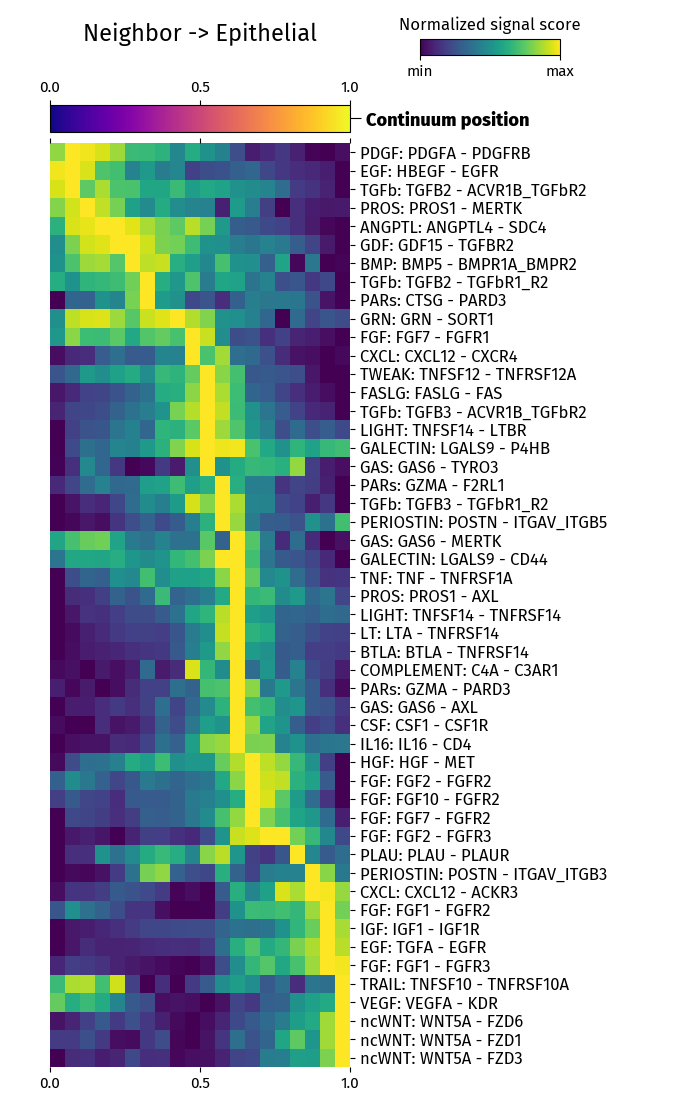

In [15]:
fig = plt.figure(figsize=(7, 11))
plt.subplots_adjust(left=0, right=1, top=0.87, bottom=0.03)
gs = gridspec.GridSpec(1, 3, width_ratios=[1, 6, 7], wspace=0, hspace=0.08)

# heatmap
ax1 = plt.subplot(gs[1])
sns.heatmap(
    df_sorted.T,
    cmap="viridis",
    cbar_kws={"label": "Normalized signal (0-1)"},
    ax=ax1,
    cbar=False,
    linecolor="black",
    linewidths=0,
)

ax1.yaxis.tick_right()
ax1.yaxis.set_label_position("right")
ax1.set_xticks([0,bins/2, bins], labels=[0.0, 0.5, 1.0], rotation=0, fontsize=11)
ax1.tick_params("x", top=True, labeltop=False, bottom=True, labelbottom=True)
ax1.tick_params("y", rotation=0, labelsize=12)


# colorbar setting
norm = matplotlib.colors.Normalize(vmin=0, vmax=1)
center_ax = [sum(gs.get_width_ratios()[0:1])/sum(gs.get_width_ratios()), sum(gs.get_width_ratios()[0:2])/sum(gs.get_width_ratios())]
sm_cp = plt.cm.ScalarMappable(cmap="plasma", norm=norm)
sm_val = plt.cm.ScalarMappable(cmap="viridis", norm=norm)
cbar_ax_cp = fig.add_axes((center_ax[0], 0.88, center_ax[1]-center_ax[0], 0.025))
cbar_ax_val = fig.add_axes((center_ax[1]+0.1, 0.95, 1-center_ax[1]-0.3, 0.015))
cbar_cp = plt.colorbar(sm_cp, cax=cbar_ax_cp, ticks=[0.0, 0.5, 1.0], orientation="horizontal")
cbar_val = plt.colorbar(sm_val, cax=cbar_ax_val, ticks=[0.0, 1.0], orientation="horizontal")
cbar_cp.ax.set_xticklabels(['0.0', '0.5', '1.0'], fontsize=11)
cbar_val.ax.set_xticklabels(['min', "max"], fontsize=11)

cbar_val.ax.set_title("Normalized signal score", fontsize=12)

cbar_ax_cp.tick_params("x", top=True, labeltop=True, bottom=False, labelbottom=False)
cbar_ax_cp.set_yticks([0.5], labels=["Continuum position"], fontsize=13, weight=800)
cbar_ax_cp.tick_params("y", size=8)
cbar_ax_cp.yaxis.set_label_position("right")
cbar_ax_cp.yaxis.tick_right()

# title setting
ti_ax = fig.add_axes((center_ax[0]-0.1, 0.92, center_ax[1]-center_ax[0]+0.2, 0.07))
ti_ax.text(s=tl , x=0.5, y=0.7, ha="center", va="center", fontsize=17)
ti_ax.axis("off")

plt.savefig(f"{WORK_PATH}Figure/032_Interaction_Cposition_{sv}.png", dpi=500, format="png", bbox_inches=None)

In [16]:
for d, di in [(0, "nei2epi"), (1, "epi2nei")]:

    df = merge_df_top[d].copy()

    # Peak bin
    peak_bin = df.idxmax(axis=0)

    weighted_bin = (
        df.mul(df.index.to_numpy(), axis=0).sum(axis=0)
        / df.sum(axis=0)
    )

    order_df = pd.DataFrame({
        "peak_bin": peak_bin,
        "weighted_bin": weighted_bin
    })

    pathway_order = (
        order_df
        .sort_values(["peak_bin", "weighted_bin"])
        .index
    )

    df_sorted = df[pathway_order]

    # Source Data
    df_source = df_sorted.T.copy()

    df_source.index.name = "Interaction"
    df_source.columns.name = "Continuum_bin"

    df_source = (
        df_source
        .reset_index()
        .melt(
            id_vars="Interaction",
            var_name="Continuum_bin",
            value_name="Normalized_signal_score"
        )
    )


    df_source.to_csv(f"{WORK_PATH}CSV/032_Interaction_Cposition_{di}_source_data.csv", index=True)


## Example pathway

In [17]:
temp_df = cellchat_db_f[["pathway_name", "interaction_name"]].copy()

In [18]:
ex_int = {
    "TGFb":["TGFB1 - TGFbR1_R2", "TGFB2 - TGFbR1_R2", "TGFB3 - TGFbR1_R2"],
    "PERIOSTIN":["POSTN - ITGAV_ITGB3", "POSTN - ITGAV_ITGB5"],
    "COMPLEMENT":['C4A - C3AR1', 'C4A - CR2', 'C5 - C5AR1'],
}

In [19]:
interaction = "TGFb"
drct = 0
ex_df = pd.DataFrame({key: merge_df[drct].loc[:,key] for key in ex_int[interaction]})

In [20]:
scaled = ex_df.copy()

for col in ex_int[interaction]:
    scaled[col] = (
        (ex_df[col] - ex_df[col].min()) /
        (ex_df[col].max() - ex_df[col].min())
    )

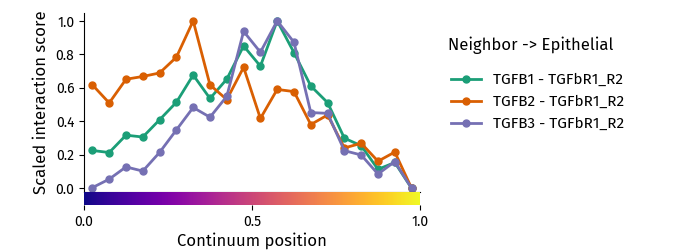

In [21]:
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(7, 2.5),
    height_ratios=(6, 0.45),
    gridspec_kw={"hspace": 0}
)

fig.subplots_adjust(left=0.12, right=0.6, bottom=0.18, top=0.95)

# Upper panel
cmap = plt.get_cmap("Dark2") 
for n,col in enumerate(scaled.columns):
    ax1.plot(scaled[col], label=col, lw=2, c=cmap(n), marker="o", markersize=5)
ax1.set_xlim(-0.5,bins-0.5)
ax1.legend(loc="center left", bbox_to_anchor=(1.05, 0.5), frameon=False, fontsize=11)

ax1.spines[["top", "right"]].set_visible(False)
ax1.set_ylim(-0.02,1.05)
ax1.set_ylabel("Scaled interaction score", fontsize=12)
ax1.tick_params(axis="x", bottom=False, labelbottom=False)

# Lower panel: continuum color bar
n_bins = scaled.shape[0]
gradient = np.linspace(0, 1, 500)[np.newaxis, :]

ax2.imshow(
    gradient,
    aspect="auto",
    cmap="plasma",
    extent=[0, n_bins - 1, 0, 1],
    interpolation="bilinear"
)
ax2.set_yticks([])
ax2.set_xlim(0, n_bins - 1)

ax2.set_xticks([0, (n_bins - 1)/2,n_bins - 1])
ax2.set_xticklabels(["0.0", "0.5", "1.0"])
ax2.set_xlabel("Continuum position", labelpad=2, fontsize=12)
ax2.spines[:].set_visible(False)

ft = ["Neighbor", "Epithelial"]
if drct != 0:
    ft = ft[::-1]
    
fig.text(s=f"{ft[0]} -> {ft[1]}", x= 0.64, y=0.8, fontsize=12)

plt.savefig(f"{WORK_PATH}Figure/032_{interaction}_change.png", dpi=500, format="png", bbox_inches=None)
plt.show()

In [22]:
# Direction
direction = "Neighbor_to_Epithelial" if drct == 0 else "Epithelial_to_Neighbor"

# Source Data
df_source = scaled.copy()

# Continuum position (0–1)
df_source.insert(
    0,
    "Continuum_position",
    np.linspace(0, 1, len(df_source))
)

df_source.index.name = "Continuum_bin"

# Long format
df_source = (
    df_source
    .reset_index()
    .melt(
        id_vars=["Continuum_bin", "Continuum_position"],
        var_name="Cell_subtype",
        value_name="Scaled_interaction_score"
    )
)

df_source.to_csv(f"{WORK_PATH}CSV/032_{interaction}_change_source_data.csv", index=True)
df_source

,Continuum_bin,Continuum_position,Cell_subtype,Scaled_interaction_score
0,0,0.000000,TGFB1 - TGFbR1_R2,0.225485
1,1,0.052632,TGFB1 - TGFbR1_R2,0.213319
2,2,0.105263,TGFB1 - TGFbR1_R2,0.316978
3,3,0.157895,TGFB1 - TGFbR1_R2,0.305926
4,4,0.210526,TGFB1 - TGFbR1_R2,0.409061
5,5,0.263158,TGFB1 - TGFbR1_R2,0.513590
6,6,0.315789,TGFB1 - TGFbR1_R2,0.676354
7,7,0.368421,TGFB1 - TGFbR1_R2,0.536256
8,8,0.421053,TGFB1 - TGFbR1_R2,0.651914
9,9,0.473684,TGFB1 - TGFbR1_R2,0.850296


## interaction detail (VEGFA - KDR)

In [23]:
with open(f"{pathway_dir}/VEGFA - KDR.pkl", "rb") as f:
    obj = pickle.load(f)

obj_i2n = obj["int_to_nei"]

meta = celltype_c.set_index("index")[["sample", "subtype", "cell_type_major"]]
epi_meta = meta[meta["cell_type_major"] == "Epithelial"].copy()

valid_set = set(valid_indices)

sender_scores = defaultdict(float)

for (s, r), score in obj_i2n.items():
    if s not in valid_set:
        continue

    sender_scores[s] += float(np.asarray(score).sum())

sender_df = epi_meta.loc[epi_meta.index.intersection(valid_set)].copy()

sender_df["score"] = pd.Series(sender_scores, dtype=float).reindex(sender_df.index, fill_value=0)

In [24]:
summary_df = (
    sender_df
    .groupby("subtype")
    .agg(
        n_cells=("score", "size"),
        mean_score=("score", "mean"),
        median_score=("score", "median"),
        total_score=("score", "sum"),
        positive_fraction=("score", lambda x: (x > 0).mean())
    )
    .sort_values("mean_score", ascending=False)
)

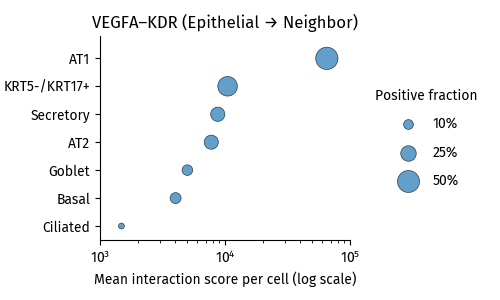

In [25]:
plot_df = summary_df.sort_values("mean_score", ascending=True).copy()

size_scale = 500
sizes = plot_df["positive_fraction"] * size_scale

plot_df["mean_score_plot"] = plot_df["mean_score"].replace(0, np.nan)

fig, ax = plt.subplots(figsize=(5, 3))
fig.subplots_adjust(left=0.2, bottom=0.2, right=0.7)
y = np.arange(len(plot_df))

dot_color = "tab:blue"

ax.scatter(
    plot_df["mean_score_plot"],
    y,
    s=sizes,
    color=dot_color,
    alpha=0.7,
    edgecolors="black",
    linewidths=0.5
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df.index)
ax.set_xscale("log")
ax.set_xlim(10e2, 10e4)
ax.set_ylim(-0.5, 6.8)
ax.set_xlabel("Mean interaction score per cell (log scale)")
ax.set_ylabel("")
ax.set_title("VEGFA–KDR (Epithelial → Neighbor)")

legend_fracs = [0.1, 0.25, 0.5]

handles = [
    ax.scatter(
        [], [],
        s=f * size_scale,
        color=dot_color,
        alpha=0.7,
        edgecolors="black",
        linewidths=0.5
    )
    for f in legend_fracs
]

labels = [f"{f:.0%}" for f in legend_fracs]

ax.legend(
    handles,
    labels,
    title="Positive fraction",
    scatterpoints=1,
    markerscale=1,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(1.05,0.5),
    labelspacing=1
)

ax.spines[["top", "right"]].set_visible(False)

fig.savefig(f"{WORK_PATH}Figure/032_VEGFA_KDR_epithelial.png", dpi=500, format="png", bbox_inches=None)

In [26]:
source_df = (
    summary_df[
        ["n_cells", "mean_score", "positive_fraction"]
    ]
    .sort_values("mean_score", ascending=False)
    .reset_index()
    .rename(columns={
        "subtype": "Epithelial_subtype",
        "n_cells": "N_cells",
        "mean_score": "Mean_interaction_score",
        "positive_fraction": "Positive_fraction"
    })
)

display(source_df)

# CSV
source_df.to_csv(
    f"{WORK_PATH}CSV/032_VEGFA_KDR_epithelial_sender_source_data.csv",
    index=False
)

,Epithelial_subtype,N_cells,Mean_interaction_score,Positive_fraction
0,AT1,7952,65247.584775,0.514965
1,KRT5-/KRT17+,6461,10487.262896,0.397462
2,Secretory,10483,8751.017380,0.210341
3,AT2,16898,7763.982169,0.206533
4,Goblet,4037,5001.269346,0.116919
5,Basal,11463,4026.083102,0.124400
6,Ciliated,4037,1484.528028,0.035422


In [27]:
subtype_map = meta["subtype"].to_dict()

at1_indices = set(meta.index[meta["subtype"] == "AT1"]) & set(valid_indices)

n_at1 = len(at1_indices)

# AT1 sender × receiver subtype
sender_receiver_scores = defaultdict(float)

# score of eache receiver cell from AT1
receiver_scores = defaultdict(float)

for (s, r), score in obj_i2n.items():

    if s not in at1_indices:
        continue

    if r not in subtype_map:
        continue

    receiver_subtype = subtype_map[r]
    val = float(np.asarray(score).sum())

    sender_receiver_scores[(s, receiver_subtype)] += val
    receiver_scores[r] += val

In [28]:
# sender × receiver subtype
sr_df = pd.DataFrame(
    [(s, subtype, score) for (s, subtype), score in sender_receiver_scores.items()],
    columns=["sender_idx", "receiver_subtype", "score"]
)

receiver_summary = (
    sr_df.groupby("receiver_subtype")
    .agg(
        total_score=("score", "sum"),
        n_positive_senders=("score", lambda x: (x > 0).sum())
    )
)

receiver_summary["n_AT1"] = n_at1
receiver_summary["mean_score"] = receiver_summary["total_score"] / n_at1
receiver_summary["positive_fraction"] =  receiver_summary["n_positive_senders"] / n_at1
receiver_summary["contribution_pct"] = receiver_summary["total_score"] / receiver_summary["total_score"].sum() * 100

receiver_summary = receiver_summary.sort_values("mean_score", ascending=False)


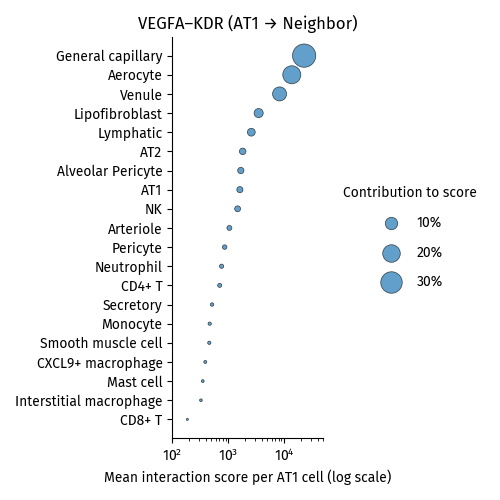

In [29]:
plot_df = receiver_summary.sort_values(
    "mean_score", ascending=True
).copy()
plot_df = plot_df.tail(20)

size_scale = 800
sizes = plot_df["contribution_pct"] * size_scale * 0.01

plot_df["mean_score_plot"] = (
    plot_df["mean_score"].replace(0, np.nan)
)


fig, ax = plt.subplots(figsize=(5, 5))
fig.subplots_adjust(left=0.32, bottom=0.15, right=0.72)

y = np.arange(len(plot_df))

dot_color = "tab:blue"

ax.scatter(
    plot_df["mean_score_plot"],
    y,
    s=sizes,
    color=dot_color,
    alpha=0.7,
    edgecolors="black",
    linewidths=0.5
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df.index)
ax.set_xlim(1e2, 5e4)
ax.set_xscale("log")
ax.set_xlabel("Mean interaction score per AT1 cell (log scale)")
ax.set_title("VEGFA–KDR (AT1 → Neighbor)")

legend_fracs = [0.1, 0.2, 0.3]

handles = [
    ax.scatter(
        [], [],
        s=f * size_scale,
        color=dot_color,
        alpha=0.7,
        edgecolors="black",
        linewidths=0.5
    )
    for f in legend_fracs
]

ax.legend(
    handles,
    [f"{f:.0%}" for f in legend_fracs],
    title="Contribution to score",
    scatterpoints=1,
    labelspacing=1.1,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(1.05, 0.5)
)

ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

fig.savefig(f"{WORK_PATH}Figure/032_VEGFA_KDR_reciever.png", dpi=500, format="png", bbox_inches=None)

In [30]:
source_df = (
    receiver_summary[
        ["n_positive_senders", "mean_score", "contribution_pct"]
    ]
    .sort_values("mean_score", ascending=False)
    .reset_index()
    .rename(columns={
        "receiver_subtype": "Reciever_subtype",
        "n_positive_senders": "N_positive_senders",
        "mean_score": "Mean_interaction_score",
        "contribution_pct": "Contribution_to_score",
    })
)

source_df.to_csv(f"{WORK_PATH}CSV/032_VEGFA_KDR_reciver_source_data.csv", index=False)

In [31]:
cp_df = pd.read_csv(f"{WORK_PATH}CSV/021_epithelial_cPosition.csv", index_col="cell_id")

In [32]:
top10 = (
    receiver_summary
    .sort_values("mean_score", ascending=False)
    .head(10)
    .index.tolist()
)

meta = celltype_c.reset_index().set_index("index")

valid_set = set(valid_indices)

at1_meta = meta.loc[(meta["subtype"] == "AT1") & (meta.index.isin(valid_set))].copy()

at1_meta["cp"] = at1_meta["cell_id"].map(cp_df["C_position"])
at1_meta = at1_meta.dropna(subset=["cp"])

# 20 bins
n_bins = 20
edges = np.linspace(0, 1, n_bins + 1)

at1_meta["bin"] = pd.cut(
    at1_meta["cp"],
    bins=edges,
    labels=False,
    include_lowest=True
)

at1_meta = at1_meta.dropna(subset=["bin"])
at1_meta["bin"] = at1_meta["bin"].astype(int)

at1_set = set(at1_meta.index)
subtype_map = meta["subtype"].to_dict()

# AT1 sender × receiver subtype
scores = defaultdict(float)

for (s, r), score in obj_i2n.items():

    if s not in at1_set:
        continue

    rec_subtype = subtype_map.get(r)

    if rec_subtype not in top10:
        continue

    scores[(s, rec_subtype)] += float(np.asarray(score).sum())

sr_df = pd.DataFrame(
    [(s, sub, val) for (s, sub), val in scores.items()],
    columns=["sender_idx", "receiver_subtype", "score"]
)

score_mat = (
    sr_df.pivot_table(
        index="sender_idx",
        columns="receiver_subtype",
        values="score",
        aggfunc="sum",
        fill_value=0
    )
    .reindex(index=at1_meta.index, columns=top10, fill_value=0)
)

score_by_bin = (
    score_mat
    .groupby(at1_meta["bin"])
    .mean()
    .reindex(range(n_bins))
)

positive_by_bin = score_mat.gt(0).groupby(at1_meta["bin"]).mean().reindex(range(n_bins))

display(score_by_bin)

receiver_subtype,General capillary,Aerocyte,Venule,Lipofibroblast,Lymphatic,AT2,Alveolar Pericyte,AT1,NK,Arteriole
bin,,,,,,,,,,
0,36045.468897,20776.736623,3950.746735,5080.693630,2322.816423,2566.655226,2450.890146,2595.076501,2403.041744,1135.649274
1,32528.553744,20565.245595,7406.917338,4097.439160,3087.487791,2723.002537,2239.566786,1965.278033,1993.577163,1302.298132
2,24682.345130,17431.973075,8947.272121,3658.039339,3405.756881,2242.828534,1889.887646,1822.221902,1361.838762,1210.670258
3,16200.466176,10157.316417,8300.853082,2478.203159,2265.209569,1399.259133,1229.506530,1128.381262,923.029695,953.158175
4,12113.030296,7024.068589,10585.933677,2521.843913,2643.070336,1183.893394,1113.094067,926.516748,717.403050,812.269259
5,6743.916442,3441.139725,14776.918016,2124.337602,2936.378929,763.491367,771.836464,673.470663,435.785963,920.511986
6,3385.824556,1947.469546,14522.045414,1516.508610,2730.048614,522.978182,521.490782,313.321559,230.694081,780.041252
7,3012.985515,1569.409160,14811.824928,1446.872905,3113.219214,321.209696,545.690214,274.276909,313.962581,869.354973
8,1452.998501,756.426403,13547.471876,1079.999800,1904.110532,195.517204,420.838780,172.780395,247.325138,810.781362


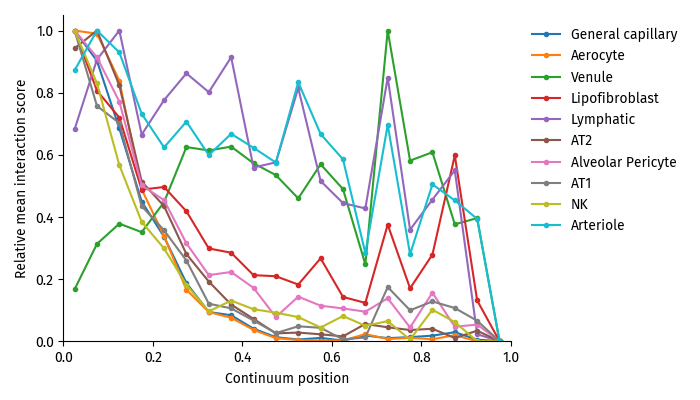

In [33]:
score_scaled = score_by_bin.div(
    score_by_bin.max(axis=0).replace(0, np.nan),
    axis=1
)

bin_centers = (edges[:-1] + edges[1:]) / 2

fig, ax = plt.subplots(figsize=(7, 4))

for subtype in top10:
    ax.plot(
        bin_centers,
        score_scaled[subtype],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=subtype
    )

ax.set_xlabel("Continuum position")
ax.set_ylabel("Relative mean interaction score")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)

ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

fig.savefig(f"{WORK_PATH}Figure/032_VEGFA_KDR_by_bin.png", dpi=500, format="png", bbox_inches=None)

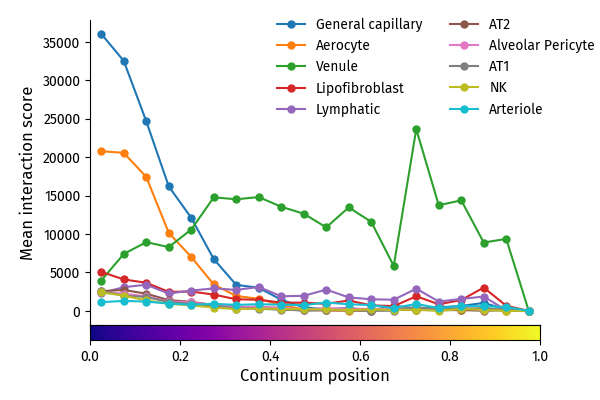

In [34]:
bin_centers = (edges[:-1] + edges[1:]) / 2

fig, (ax1, ax2) = plt.subplots(2,1,figsize=(6, 4), height_ratios=(20,1))
fig.subplots_adjust(hspace=0, left=0.15, right=0.9, bottom=0.15, top=0.95)
bin_centers = (edges[:-1] + edges[1:]) / 2

for subtype in top10:
    ax1.plot(
        bin_centers,
        score_by_bin[subtype],
        marker="o",
        markersize=5,
        linewidth=1.5,
        label=subtype
    )

ax1.set_xlabel("")
ax1.set_ylabel("Mean interaction score", fontsize=12)
ax1.set_xlim(0, 1)
ax1.set_xticklabels([])
# ax.set_ylim(0, 1.05)

ax1.legend(
    bbox_to_anchor=(1.15, 1.05),
    loc="upper right",
    frameon=False,
    ncols=2
)

ax1.spines[["top", "right"]].set_visible(False)
ax1

gradient = np.linspace(0, 1, 500)[np.newaxis, :]

ax2.imshow(
    gradient,
    aspect="auto",
    cmap="plasma",
    extent=[0, 1, 0, 1],
    interpolation="bilinear"
)
ax2.set_yticks([])
ax2.set_xlim(0, 1)

ax2.set_xticks([0.2*n for n in range(6)])

ax2.set_xlabel("Continuum position", labelpad=2, fontsize=12)

fig.savefig(f"{WORK_PATH}Figure/032_VEGFA_KDR_by_bin_rawScore.png", dpi=500, format="png", bbox_inches=None)

In [35]:
score_source_df = score_by_bin.copy()
score_source_df.insert(0, "Continuum_position", bin_centers)

score_source_df.to_csv(f"{WORK_PATH}CSV/032_VEGFA_KDR_by_bin_rawScore_source_data.csv", index=False)

In [36]:
epi_meta = meta.loc[
    (meta["cell_type_major"] == "Epithelial") &
    (meta.index.isin(valid_set))
].copy()

epi_meta["cp"] = epi_meta["cell_id"].map(cp_df["C_position"])
epi_meta = epi_meta.dropna(subset=["cp"])

epi_meta["bin"] = pd.cut(
    epi_meta["cp"],
    bins=edges,
    labels=False,
    include_lowest=True
)

n_epi = epi_meta.groupby("bin", observed=True).size()
n_at1 = at1_meta.groupby("bin").size()

at1_fraction = (
    n_at1.reindex(range(n_bins), fill_value=0)
    / n_epi.reindex(range(n_bins), fill_value=0).replace(0, np.nan)
)

score_per_epithelial = score_by_bin.mul(at1_fraction, axis=0)

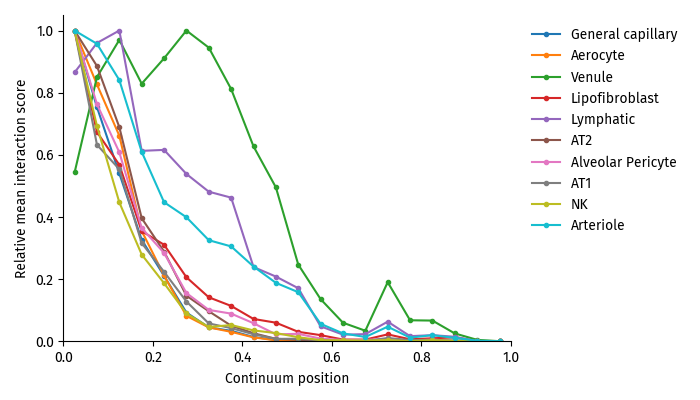

In [37]:
score_scaled = score_per_epithelial.div(
    score_per_epithelial.max(axis=0).replace(0, np.nan),
    axis=1
)

bin_centers = (edges[:-1] + edges[1:]) / 2

fig, ax = plt.subplots(figsize=(7, 4))

for subtype in top10:
    ax.plot(
        bin_centers,
        score_scaled[subtype],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=subtype
    )

ax.set_xlabel("Continuum position")
ax.set_ylabel("Relative mean interaction score")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)

ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

fig.savefig(f"{WORK_PATH}Figure/032_VEGFA_KDR_per_epithelial.png", dpi=500, format="png", bbox_inches=None)

In [38]:
# AT1 counts of each continumm bin
n_at1_bin = at1_meta.groupby("bin").size().reindex(range(n_bins), fill_value=0)
n_epi_bin = epi_meta.groupby("bin").size().reindex(range(n_bins), fill_value=0)

n_samples_at1 = at1_meta.groupby("bin")["sample"].nunique().reindex(range(n_bins), fill_value=0)

qc_df = pd.DataFrame({
    "continuum_position": bin_centers,
    "n_AT1": n_at1_bin,
    "n_epithelial": n_epi_bin,
    "AT1_fraction": n_at1_bin / n_epi_bin.replace(0, np.nan),
    "n_samples_AT1": n_samples_at1
})

score_source_df.to_csv(f"{WORK_PATH}CSV/032_VEGFA_KDR_AT1_cnt_source_data.csv", index=False)

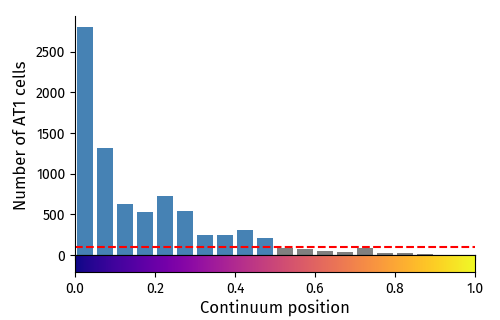

In [39]:
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(5, 3.2),
    sharex=True,
    height_ratios=(14,1)
)

fig.subplots_adjust(hspace=0, top=0.95, bottom=0.15, left=0.15, right=0.95)

bar_colors = np.where(qc_df["n_AT1"] <= 100, "grey", "steelblue")

ax1.bar(bin_centers, qc_df["n_AT1"], width=0.04, color=bar_colors)

ax1.set_ylabel("Number of AT1 cells", fontsize=12)
ax1.spines[["top", "right"]].set_visible(False)
ax1.axhline(y=100, ls="--", c="red")
gradient = np.linspace(0, 1, 500)[np.newaxis, :]

ax2.imshow(
    gradient,
    aspect="auto",
    cmap="plasma",
    extent=[0, 1, 0, 1],
    interpolation="bilinear"
)
ax2.set_yticks([])
ax2.set_xlim(0, 1)

ax2.set_xticks([0.2*n for n in range(6)])

ax2.set_xlabel("Continuum position", labelpad=2, fontsize=12)

fig.savefig(f"{WORK_PATH}Figure/032_VEGFA_KDR_AT1_cnt.png", dpi=500, format="png", bbox_inches=None)

In [40]:
df_source = pd.DataFrame({
    "Continuum_position": np.asarray(bin_centers),
    "Number_of_AT1_cells": np.asarray(qc_df["n_AT1"]),
})

df_source["Low_count_flag_n_AT1_le_100"] = (
    df_source["Number_of_AT1_cells"] <= 100
)

df_source["Bar_color"] = np.where(
    df_source["Low_count_flag_n_AT1_le_100"],
    "grey",
    "steelblue"
)
df_source.to_csv(f"{WORK_PATH}CSV/032_VEGFA_KDR_AT1_cnt.csv", index=True)

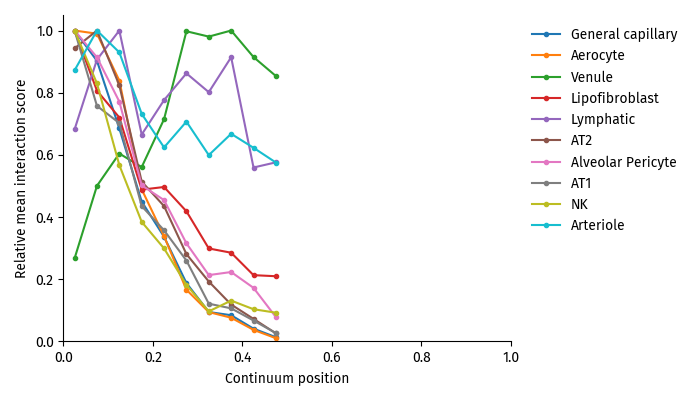

In [41]:
valid_bins = (
    (qc_df["n_AT1"] >= 100) &
    (qc_df["n_samples_AT1"] >= 3)
).to_numpy()

score_filtered = score_by_bin.copy()
score_filtered.loc[~valid_bins, :] = np.nan

score_scaled_filtered = score_filtered.div(
    score_filtered.max(axis=0).replace(0, np.nan), axis=1
)

fig, ax = plt.subplots(figsize=(7, 4))

for subtype in top10:
    ax.plot(
        bin_centers,
        score_scaled_filtered[subtype],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=subtype
    )

ax.set_xlabel("Continuum position")
ax.set_ylabel("Relative mean interaction score")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)

ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### VEGFA expression in AT1 along the continuum

In [42]:
adata = sc.read_h5ad(f"{WORK_PATH}AnnData/spatial_merged.h5ad")

In [43]:
expr_df = at1_meta[["cell_id", "sample", "cp", "bin"]].copy()

In [44]:
cell_ids = expr_df["cell_id"].tolist()
adata_at1 = adata[cell_ids, :]

In [45]:
X = adata_at1.X
gene_idx = adata_at1.var_names.get_loc("VEGFA")
vegfa = X[:, gene_idx].toarray().ravel()
total_counts = np.asarray(X.sum(axis=1)).ravel()

In [46]:
expr_df["VEGFA_raw"] = vegfa
expr_df["VEGFA_per10k"] = vegfa / np.where(total_counts > 0, total_counts, np.nan) * 10000
expr_df["VEGFA_positive"] = vegfa > 0

expr_df.head()

,cell_id,sample,cp,bin,VEGFA_raw,VEGFA_per10k,VEGFA_positive
index,,,,,,,
4,aaadddld-0,AF_s2,0.015689,0,1.0,14.577260,True
19,aaanbche-0,AF_s2,0.014786,0,2.0,91.324196,True
24,aaanmkep-0,AF_s2,0.015741,0,4.0,179.372208,True
31,aabcikcc-0,AF_s2,0.015686,0,0.0,0.000000,False
43,aabihoio-0,AF_s2,0.015204,0,4.0,128.205124,True


In [47]:
expr_by_bin = (
    expr_df
    .groupby("bin")
    .agg(
        n_AT1=("VEGFA_raw", "size"),
        n_samples=("sample", "nunique"),
        mean_VEGFA_raw=("VEGFA_raw", "mean"),
        mean_VEGFA_per10k=("VEGFA_per10k", "mean"),
        positive_fraction=("VEGFA_positive", "mean")
    )
    .reindex(range(n_bins))
)

valid_bins = (expr_by_bin["n_AT1"] >= 100) & (expr_by_bin["n_samples"] >= 3)

expr_by_bin.loc[
    ~valid_bins,
    ["mean_VEGFA_raw", "mean_VEGFA_per10k", "positive_fraction"]
] = np.nan

expr_by_bin["continuum_position"] = bin_centers

display(expr_by_bin)

,n_AT1,n_samples,mean_VEGFA_raw,mean_VEGFA_per10k,positive_fraction,continuum_position
bin,,,,,,
0,2800,4,1.622857,39.084248,0.580714,0.025
1,1316,6,1.310790,34.494064,0.544073,0.075
2,621,5,1.238325,31.970951,0.550725,0.125
3,528,6,0.986742,25.069956,0.473485,0.175
4,729,6,0.994513,24.489786,0.454047,0.225
5,546,6,1.148352,24.088873,0.485348,0.275
6,244,6,0.807377,18.649704,0.418033,0.325
7,246,6,1.032520,17.906546,0.443089,0.375
8,307,6,1.019544,15.678866,0.429967,0.425


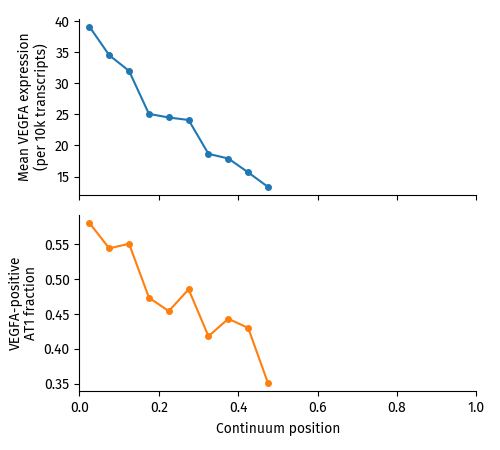

In [48]:
fig, axes = plt.subplots(2, 1, figsize=(5, 4.5), sharex=True)

x = expr_by_bin["continuum_position"]

# Mean expression
axes[0].plot(
    x,
    expr_by_bin["mean_VEGFA_per10k"],
    marker="o",
    markersize=4,
    color="tab:blue"
)

axes[0].set_ylabel("Mean VEGFA expression\n(per 10k transcripts)")

# Positive fraction
axes[1].plot(
    x,
    expr_by_bin["positive_fraction"],
    marker="o",
    markersize=4,
    color="tab:orange"
)

axes[1].set_ylabel("VEGFA-positive\nAT1 fraction")
axes[1].set_xlabel("Continuum position")

for ax in axes:
    ax.set_xlim(0, 1)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [49]:
interaction = score_by_bin[["General capillary", "Aerocyte"]].sum(axis=1, min_count=1)

expression = expr_by_bin["mean_VEGFA_per10k"].copy()

interaction = interaction.where(valid_bins)
expression = expression.where(valid_bins)

interaction_scaled = interaction / interaction.max()
expression_scaled = expression / expression.max()


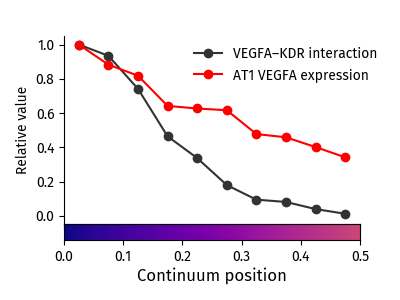

In [50]:

fig, (ax1,ax2) = plt.subplots(2,1,figsize=(4, 3), height_ratios=(12,1))
fig.subplots_adjust(hspace=0, bottom=0.2, left=0.16)

ax1.plot(
    bin_centers,
    interaction_scaled,
    marker="o",
    label="VEGFA–KDR interaction",
    color="#333333"
)

ax1.plot(
    bin_centers,
    expression_scaled,
    marker="o",
    label="AT1 VEGFA expression",
    color="red"
)

ax1.set_xlabel("")
ax1.set_xticklabels([])
ax1.set_ylabel("Relative value")
ax1.set_xlim(0, 0.5)
ax1.set_ylim(-0.05, 1.05)

ax1.legend(frameon=False, bbox_to_anchor=(1.1,0.85), loc="center right")
ax1.spines[["top", "right"]].set_visible(False)

gradient = np.linspace(0, 1, 500)[np.newaxis, :]

ax2.imshow(
    gradient,
    aspect="auto",
    cmap="plasma",
    extent=[0, 1, 0, 1],
    interpolation="bilinear"
)
ax2.set_yticks([])
ax2.set_xlim(0, 0.5)

ax2.set_xticks([0.1*n for n in range(6)])

ax2.set_xlabel("Continuum position", labelpad=2, fontsize=12)

fig.savefig(f"{WORK_PATH}Figure/032_VEGFA_KDR_AT1_int_exp.png", dpi=500, format="png", bbox_inches=None)

In [51]:
df_source = pd.DataFrame({
    "Continuum_position": np.asarray(bin_centers),
    "VEGFA_KDR_interaction": np.asarray(interaction_scaled),
    "AT1_VEGFA_expression": np.asarray(expression_scaled)
})

df_source = df_source.loc[
    df_source["Continuum_position"] <= 0.5
].reset_index(drop=True)

df_source.to_csv(f"{WORK_PATH}CSV/032_VEGFA_KDR_AT1_int_exp_source_data.csv", index=True)
df_source

,Continuum_position,VEGFA_KDR_interaction,AT1_VEGFA_expression
0,0.025,1.000000,1.000000
1,0.075,0.934385,0.882557
2,0.125,0.741160,0.818001
3,0.175,0.463864,0.641434
4,0.225,0.336789,0.626590
5,0.275,0.179244,0.616332
6,0.325,0.093859,0.477167
7,0.375,0.080644,0.458153
8,0.425,0.038883,0.401156
9,0.475,0.011677,0.341356


### Reciever side

In [52]:
target_subtypes = ["General capillary", "Aerocyte", "Venule"]

RADIUS = 300
SIGMA = 150

In [53]:
bin_qc = at1_meta.groupby("bin").agg(n_AT1=("sample", "size"), n_samples=("sample", "nunique"))
valid_bins = bin_qc.index[(bin_qc["n_AT1"] >= 100) & (bin_qc["n_samples"] >= 3)]
at1_use = at1_meta[at1_meta["bin"].isin(valid_bins)].copy()

In [54]:
receiver_meta = meta[meta["subtype"].isin(target_subtypes)].copy()

In [55]:
receiver_ids = receiver_meta["cell_id"].astype(str)
row_idx = adata.obs_names.get_indexer(receiver_ids)

In [56]:
X = adata.X
gene_idx = adata.var_names.get_loc("KDR")
kdr = X[row_idx, gene_idx].toarray().ravel()

In [57]:
total_counts = np.asarray(X[row_idx, :].sum(axis=1)).ravel()
receiver_meta["KDR_raw"] = kdr
receiver_meta["KDR_per10k"] = kdr / np.where(total_counts > 0, total_counts, np.nan) * 10000
receiver_meta["KDR_positive"] = kdr > 0

In [58]:
def attach_coordinates(df, adata):
    df = df.copy()

    ids = df["cell_id"].astype(str)
    idx = adata.obs_names.get_indexer(ids)

    assert (idx >= 0).all(), "Missing cell IDs"

    if {"x_centroid", "y_centroid"}.issubset(adata.obs.columns):
        xy = adata.obs.iloc[idx][
            ["x_centroid", "y_centroid"]
        ].to_numpy(dtype=float)
    else:
        xy = np.asarray(
            adata.obsm["spatial"][idx, :2],
            dtype=float
        )

    df["x"] = xy[:, 0]
    df["y"] = xy[:, 1]

    return df


at1_use = attach_coordinates(at1_use, adata)
receiver_meta = attach_coordinates(receiver_meta, adata)

In [59]:
records = []

for sample, at1_sample in at1_use.groupby("sample"):

    receiver_sample = receiver_meta[
        receiver_meta["sample"] == sample
    ]

    at1_xy = at1_sample[["x", "y"]].to_numpy()

    for subtype in target_subtypes:

        rec = receiver_sample[
            receiver_sample["subtype"] == subtype
        ]

        if len(rec) == 0:
            continue

        rec_xy = rec[["x", "y"]].to_numpy()
        rec_kdr = rec["KDR_per10k"].to_numpy()
        rec_positive = rec["KDR_positive"].to_numpy()

        tree = cKDTree(rec_xy)

        neighbors = tree.query_ball_point(
            at1_xy,
            r=RADIUS
        )

        for (sender_idx, sender), ids in zip(
            at1_sample.iterrows(),
            neighbors
        ):

            n = len(ids)

            if n == 0:
                records.append({
                    "sender_idx": sender_idx,
                    "sample": sample,
                    "bin": sender["bin"],
                    "cp": sender["cp"],
                    "receiver_subtype": subtype,
                    "n_receiver": 0,
                    "weighted_n_receiver": 0,
                    "weighted_KDR_mean": np.nan,
                    "weighted_KDR_positive_fraction": np.nan,
                    "weighted_KDR_sum": 0
                })
                continue

            distance = np.linalg.norm(
                rec_xy[ids] -
                sender[["x", "y"]].to_numpy(dtype=float),
                axis=1
            )

            # Gaussian distance weighting
            weights = np.exp(
                -distance**2 / (2 * SIGMA**2)
            )

            weighted_n = weights.sum()

            weighted_kdr_sum = np.sum(
                weights * rec_kdr[ids]
            )

            weighted_kdr_mean = (
                weighted_kdr_sum / weighted_n
            )

            weighted_positive_fraction = (
                np.sum(weights * rec_positive[ids])
                / weighted_n
            )

            records.append({
                "sender_idx": sender_idx,
                "sample": sample,
                "bin": sender["bin"],
                "cp": sender["cp"],
                "receiver_subtype": subtype,
                "n_receiver": n,
                "weighted_n_receiver": weighted_n,
                "weighted_KDR_mean": weighted_kdr_mean,
                "weighted_KDR_positive_fraction":
                    weighted_positive_fraction,
                "weighted_KDR_sum": weighted_kdr_sum
            })

receiver_at1_df = pd.DataFrame(records)

display(receiver_at1_df.head())

,sender_idx,sample,bin,cp,receiver_subtype,n_receiver,weighted_n_receiver,weighted_KDR_mean,weighted_KDR_positive_fraction,weighted_KDR_sum
0,4,AF_s2,0,0.015689,General capillary,93,43.087605,9.095388,0.227428,391.898486
1,19,AF_s2,0,0.014786,General capillary,105,46.001071,8.755100,0.212307,402.743976
2,24,AF_s2,0,0.015741,General capillary,99,46.709018,9.236442,0.224363,431.425162
3,31,AF_s2,0,0.015686,General capillary,95,45.773423,9.366508,0.228689,428.737145
4,43,AF_s2,0,0.015204,General capillary,101,51.116195,9.461082,0.195682,483.614508


In [60]:
receiver_by_bin = (
    receiver_at1_df
    .groupby(["receiver_subtype", "bin"])
    .agg(
        n_AT1=("sender_idx", "size"),
        mean_n_receiver=("n_receiver", "mean"),
        mean_weighted_n_receiver=(
            "weighted_n_receiver", "mean"
        ),
        mean_KDR_expression=(
            "weighted_KDR_mean", "mean"
        ),
        mean_KDR_positive_fraction=(
            "weighted_KDR_positive_fraction", "mean"
        ),
        mean_weighted_KDR_sum=(
            "weighted_KDR_sum", "mean"
        ),
        fraction_AT1_with_receiver=(
            "n_receiver", lambda x: (x > 0).mean()
        )
    )
    .reset_index()
)

receiver_by_bin["continuum_position"] = (
    receiver_by_bin["bin"].astype(float) + 0.5
) / n_bins

display(receiver_by_bin)

,receiver_subtype,bin,n_AT1,mean_n_receiver,mean_weighted_n_receiver,mean_KDR_expression,mean_KDR_positive_fraction,mean_weighted_KDR_sum,fraction_AT1_with_receiver,continuum_position
0,Aerocyte,0,2800,37.040000,17.753203,28.811490,0.497690,526.199290,0.995357,0.025
1,Aerocyte,1,1316,37.933131,18.074673,29.751635,0.498010,562.729950,0.976444,0.075
2,Aerocyte,2,621,35.351047,16.746042,28.947872,0.483929,518.651046,0.950081,0.125
3,Aerocyte,3,528,28.246212,13.239283,27.794567,0.474859,403.460957,0.897727,0.175
4,Aerocyte,4,729,21.203018,9.581263,27.155256,0.468536,294.350547,0.810700,0.225
5,Aerocyte,5,546,11.888278,5.136259,25.386918,0.482921,145.950434,0.631868,0.275
6,Aerocyte,6,244,7.934426,3.395833,26.273878,0.520142,96.202322,0.532787,0.325
7,Aerocyte,7,246,7.085366,2.928283,21.712872,0.489864,78.498928,0.512195,0.375
8,Aerocyte,8,307,3.856678,1.607972,22.186455,0.509963,36.029201,0.423453,0.425
9,Aerocyte,9,211,1.578199,0.554916,23.592378,0.553713,12.494832,0.213270,0.475


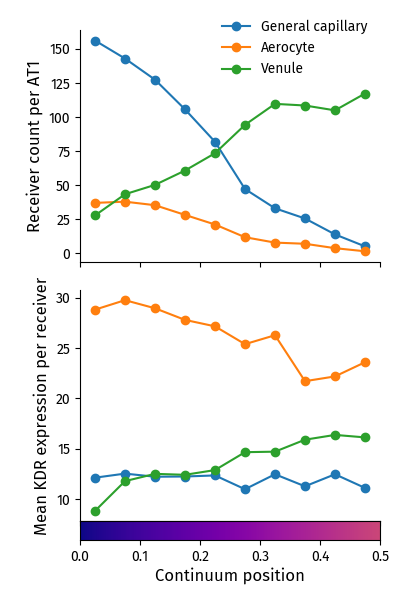

In [61]:
metrics = [
    ("mean_n_receiver", "Receiver count per AT1"),
    ("mean_KDR_expression", "Mean KDR expression per receiver"),
]

fig, (ax1, ax_b, ax2, ax_cp) = plt.subplots(
    4, 1,
    figsize=(4, 6),
    sharex=True,
    height_ratios=(25,3,25,2)
)
fig.subplots_adjust(top=0.95, left=0.2, bottom=0.1, right=0.95, hspace=0)

for ax, (metric, ylabel) in zip([ax1, ax2], metrics):

    for subtype in target_subtypes:

        temp = receiver_by_bin[
            receiver_by_bin["receiver_subtype"] == subtype
        ].sort_values("continuum_position")

        ax.plot(
            temp["continuum_position"],
            temp[metric],
            marker="o",
            markersize=6,
            label=subtype
        )

    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_xlim(0, 0.5)
    ax.spines[["top", "right"]].set_visible(False)

ax_cp.set_xlabel("Continuum position")

gradient = np.linspace(0, 1, 500)[np.newaxis, :]

ax_cp.imshow(
    gradient,
    aspect="auto",
    cmap="plasma",
    extent=[0, 1, 0, 1],
    interpolation="bilinear"
)
ax_cp.set_yticks([])
ax_cp.set_xlim(0, 0.5)

ax_cp.set_xticks([0.1*n for n in range(6)])

ax_cp.set_xlabel("Continuum position", labelpad=2, fontsize=12)

ax_b.axis("off")
ax1.legend(frameon=False, loc="upper right", bbox_to_anchor=(1,1.1))

fig.savefig(f"{WORK_PATH}Figure/032_VEGFA_KDR_rec.png", dpi=500, format="png", bbox_inches=None)


In [62]:
df_source = (
    receiver_by_bin.loc[
        (receiver_by_bin["continuum_position"] <= 0.5) &
        (receiver_by_bin["receiver_subtype"].isin(target_subtypes)),
        [
            "continuum_position",
            "receiver_subtype",
            "mean_n_receiver",
            "mean_KDR_expression"
        ]
    ]
    .copy()
    .sort_values(["receiver_subtype", "continuum_position"])
    .reset_index(drop=True)
)


df_source = df_source.rename(columns={
    "continuum_position": "Continuum_position",
    "receiver_subtype": "Receiver_subtype",
    "mean_n_receiver": "Receiver_count_per_AT1",
    "mean_KDR_expression": "Mean_KDR_expression_per_receiver"
})

df_source.to_csv(f"{WORK_PATH}CSV/032_VEGFA_KDR_rec_source_data.csv", index=True)

## interaction detatil (PDGFA - PDGFRA)

In [63]:
with open(f"{pathway_dir}/PDGFA - PDGFRA.pkl", "rb") as f:
    obj = pickle.load(f)

obj_i2n = obj["int_to_nei"]

meta = celltype_c.set_index("index")[["sample", "subtype", "cell_type_major"]]
epi_meta = meta[meta["cell_type_major"] == "Epithelial"].copy()

valid_set = set(valid_indices)

sender_scores = defaultdict(float)

for (s, r), score in obj_i2n.items():
    if s not in valid_set:
        continue

    sender_scores[s] += float(np.asarray(score).sum())

sender_df = epi_meta.loc[epi_meta.index.intersection(valid_set)].copy()

sender_df["score"] = pd.Series(sender_scores, dtype=float).reindex(sender_df.index, fill_value=0)

In [64]:
summary_df = (
    sender_df
    .groupby("subtype")
    .agg(
        n_cells=("score", "size"),
        mean_score=("score", "mean"),
        median_score=("score", "median"),
        total_score=("score", "sum"),
        positive_fraction=("score", lambda x: (x > 0).mean())
    )
    .sort_values("mean_score", ascending=False)
)

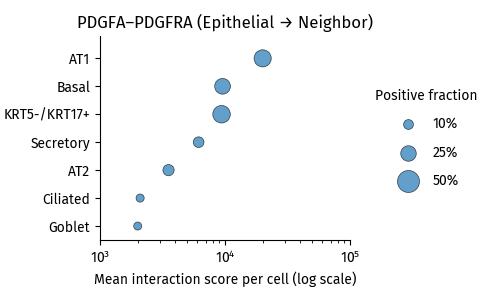

In [65]:
plot_df = summary_df.sort_values("mean_score", ascending=True).copy()

size_scale = 500
sizes = plot_df["positive_fraction"] * size_scale

plot_df["mean_score_plot"] = plot_df["mean_score"].replace(0, np.nan)

fig, ax = plt.subplots(figsize=(5, 3))
fig.subplots_adjust(left=0.2, bottom=0.2, right=0.7)
y = np.arange(len(plot_df))

dot_color = "tab:blue"

ax.scatter(
    plot_df["mean_score_plot"],
    y,
    s=sizes,
    color=dot_color,
    alpha=0.7,
    edgecolors="black",
    linewidths=0.5
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df.index)
ax.set_xscale("log")
ax.set_xlim(10e2, 10e4)
ax.set_ylim(-0.5, 6.8)
ax.set_xlabel("Mean interaction score per cell (log scale)")
ax.set_ylabel("")
ax.set_title("PDGFA–PDGFRA (Epithelial → Neighbor)")

legend_fracs = [0.1, 0.25, 0.5]

handles = [
    ax.scatter(
        [], [],
        s=f * size_scale,
        color=dot_color,
        alpha=0.7,
        edgecolors="black",
        linewidths=0.5
    )
    for f in legend_fracs
]

labels = [f"{f:.0%}" for f in legend_fracs]

ax.legend(
    handles,
    labels,
    title="Positive fraction",
    scatterpoints=1,
    markerscale=1,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(1.05,0.5),
    labelspacing=1
)

ax.spines[["top", "right"]].set_visible(False)

fig.savefig(f"{WORK_PATH}Figure/032_PDGFA_PDGFRA_epithelial.png", dpi=500, format="png", bbox_inches=None)

In [66]:
source_df = (
    summary_df[
        ["n_cells", "mean_score", "positive_fraction"]
    ]
    .sort_values("mean_score", ascending=False)
    .reset_index()
    .rename(columns={
        "subtype": "Epithelial_subtype",
        "n_cells": "N_cells",
        "mean_score": "Mean_interaction_score",
        "positive_fraction": "Positive_fraction"
    })
)

source_df.to_csv(f"{WORK_PATH}CSV/032_PDGFA_PDGFRA_epithelial_sender_source_data.csv", index=False)

In [67]:
sender_subtypes = ["KRT5-/KRT17+", "AT1", "Basal"]

subtype_map = meta["subtype"].to_dict()
valid_set = set(valid_indices)

sub_indices = {
    key: set(meta.index[meta["subtype"] == key]) & valid_set
    for key in sender_subtypes
}

n_sub = {
    key: len(sub_indices[key])
    for key in sender_subtypes
}

sender_receiver_scores = {
    key: defaultdict(float)
    for key in sender_subtypes
}

receiver_scores = {
    key: defaultdict(float)
    for key in sender_subtypes
}

sender_type_map = {
    idx: subtype
    for subtype, indices in sub_indices.items()
    for idx in indices
}

for (s, r), score in obj_i2n.items():

    sender_subtype = sender_type_map.get(s)

    if sender_subtype is None:
        continue

    receiver_subtype = subtype_map.get(r)

    if receiver_subtype is None:
        continue

    val = float(np.asarray(score).sum())

    sender_receiver_scores[sender_subtype][
        (s, receiver_subtype)
    ] += val

    receiver_scores[sender_subtype][r] += val

In [68]:
receiver_summary_dict = {key:pd.DataFrame for key in sender_subtypes}
for key in sender_subtypes:
    # sender × receiver subtype
    sr_df = pd.DataFrame(
        [(s, subtype, score) for (s, subtype), score in sender_receiver_scores[key].items()],
        columns=["sender_idx", "receiver_subtype", "score"]
    )

    receiver_summary = (
        sr_df.groupby("receiver_subtype")
        .agg(
            total_score=("score", "sum"),
            n_positive_senders=("score", lambda x: (x > 0).sum())
        )
    )
    
    receiver_summary["n_sub"] = n_sub[key]
    receiver_summary["mean_score"] = receiver_summary["total_score"] / n_sub[key]
    receiver_summary["positive_fraction"] =  receiver_summary["n_positive_senders"] / n_sub[key]
    receiver_summary["contribution_pct"] = receiver_summary["total_score"] / receiver_summary["total_score"].sum() * 100
    
    receiver_summary_dict[key] = receiver_summary.sort_values("mean_score", ascending=False)
    

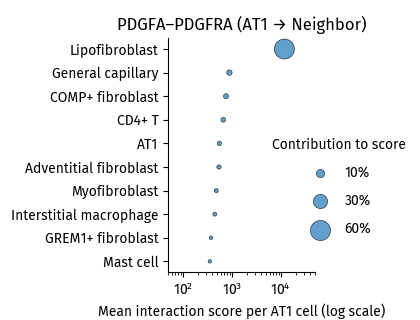

In [69]:
plot_df = receiver_summary_dict["AT1"].sort_values(
    "mean_score", ascending=True
).copy()
plot_df = plot_df.tail(10)

size_scale = 350
sizes = plot_df["contribution_pct"] * size_scale * 0.01

plot_df["mean_score_plot"] = (
    plot_df["mean_score"].replace(0, np.nan)
)

fig, ax = plt.subplots(figsize=(4.2, 3.2))
fig.subplots_adjust(left=0.4, bottom=0.15, right=0.75)

y = np.arange(len(plot_df))

dot_color = "tab:blue"

ax.scatter(
    plot_df["mean_score_plot"],
    y,
    s=sizes,
    color=dot_color,
    alpha=0.7,
    edgecolors="black",
    linewidths=0.5
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df.index)
ax.set_xlim(50, 50e3)
ax.set_xscale("log")
ax.set_xlabel("Mean interaction score per AT1 cell (log scale)")
ax.set_title("PDGFA–PDGFRA (AT1 → Neighbor)")

legend_fracs = [0.1, 0.3, 0.6]

handles = [
    ax.scatter(
        [], [],
        s=f * size_scale,
        color=dot_color,
        alpha=0.7,
        edgecolors="black",
        linewidths=0.5
    )
    for f in legend_fracs
]

ax.legend(
    handles,
    [f"{f:.0%}" for f in legend_fracs],
    title="Contribution to score",
    scatterpoints=1,
    labelspacing=1,
    frameon=False,
    loc="lower right",
    bbox_to_anchor=(1.7, 0.1)
)

ax.spines[["top", "right"]].set_visible(False)

fig.savefig(f"{WORK_PATH}Figure/032_PDGFA_PDGFRA_AT1.png", dpi=500, format="png", bbox_inches=None)

In [70]:
source_df = (
    receiver_summary_dict["AT1"][
        ["n_positive_senders", "mean_score", "contribution_pct"]
    ]
    .sort_values("mean_score", ascending=False)
    .reset_index()
    .rename(columns={
        "receiver_subtype": "Reciever_subtype",
        "n_positive_senders": "N_positive_senders",
        "mean_score": "Mean_interaction_score",
        "contribution_pct": "Contribution_to_score",
    })
)

source_df.to_csv(f"{WORK_PATH}CSV/032_PDGFA_PDGFRA_AT1_source_data.csv", index=False)

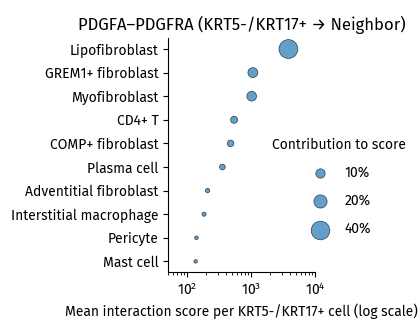

In [71]:
plot_df = receiver_summary_dict["KRT5-/KRT17+"].sort_values(
    "mean_score", ascending=True
).copy()
plot_df = plot_df.tail(10)

size_scale = 450
sizes = plot_df["contribution_pct"] * size_scale * 0.01

plot_df["mean_score_plot"] = (
    plot_df["mean_score"].replace(0, np.nan)
)


fig, ax = plt.subplots(figsize=(4.2, 3.2))
fig.subplots_adjust(left=0.4, bottom=0.15, right=0.75)

y = np.arange(len(plot_df))

dot_color = "tab:blue"

ax.scatter(
    plot_df["mean_score_plot"],
    y,
    s=sizes,
    color=dot_color,
    alpha=0.7,
    edgecolors="black",
    linewidths=0.5
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df.index)
ax.set_xlim(50, 10e3)
ax.set_xscale("log")
ax.set_xlabel("Mean interaction score per KRT5-/KRT17+ cell (log scale)")
ax.set_title("PDGFA–PDGFRA (KRT5-/KRT17+ → Neighbor)")

legend_fracs = [0.1, 0.2, 0.4]

handles = [
    ax.scatter(
        [], [],
        s=f * size_scale,
        color=dot_color,
        alpha=0.7,
        edgecolors="black",
        linewidths=0.5
    )
    for f in legend_fracs
]

ax.legend(
    handles,
    [f"{f:.0%}" for f in legend_fracs],
    title="Contribution to score",
    scatterpoints=1,
    labelspacing=1,
    frameon=False,
    loc="lower right",
    bbox_to_anchor=(1.7, 0.1)
)

ax.spines[["top", "right"]].set_visible(False)
# fig.tight_layout()

fig.savefig(f"{WORK_PATH}Figure/032_PDGFA_PDGFRA_517.png", dpi=500, format="png", bbox_inches=None)

In [72]:
source_df = (
    receiver_summary_dict["KRT5-/KRT17+"][
        ["n_positive_senders", "mean_score", "contribution_pct"]
    ]
    .sort_values("mean_score", ascending=False)
    .reset_index()
    .rename(columns={
        "receiver_subtype": "Reciever_subtype",
        "n_positive_senders": "N_positive_senders",
        "mean_score": "Mean_interaction_score",
        "contribution_pct": "Contribution_to_score",
    })
)

source_df.to_csv(f"{WORK_PATH}CSV/032_PDGFA_PDGFRA_517_source_data.csv", index=False)

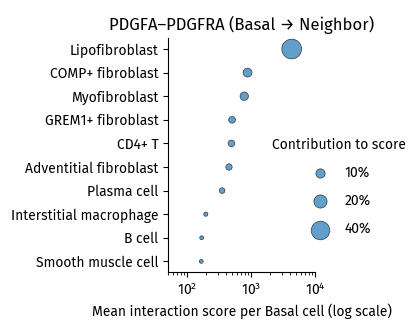

In [73]:
plot_df = receiver_summary_dict["Basal"].sort_values(
    "mean_score", ascending=True
).copy()
plot_df = plot_df.tail(10)

size_scale = 450
sizes = plot_df["contribution_pct"] * size_scale * 0.01

plot_df["mean_score_plot"] = (
    plot_df["mean_score"].replace(0, np.nan)
)


fig, ax = plt.subplots(figsize=(4.2, 3.2))
fig.subplots_adjust(left=0.4, bottom=0.15, right=0.75)

y = np.arange(len(plot_df))

dot_color = "tab:blue"

ax.scatter(
    plot_df["mean_score_plot"],
    y,
    s=sizes,
    color=dot_color,
    alpha=0.7,
    edgecolors="black",
    linewidths=0.5
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df.index)
ax.set_xlim(50, 10e3)
ax.set_xscale("log")
ax.set_xlabel("Mean interaction score per Basal cell (log scale)")
ax.set_title("PDGFA–PDGFRA (Basal → Neighbor)")

legend_fracs = [0.1, 0.2, 0.4]

handles = [
    ax.scatter(
        [], [],
        s=f * size_scale,
        color=dot_color,
        alpha=0.7,
        edgecolors="black",
        linewidths=0.5
    )
    for f in legend_fracs
]

ax.legend(
    handles,
    [f"{f:.0%}" for f in legend_fracs],
    title="Contribution to score",
    scatterpoints=1,
    labelspacing=1,
    frameon=False,
    loc="lower right",
    bbox_to_anchor=(1.7, 0.1)
)

ax.spines[["top", "right"]].set_visible(False)

fig.savefig(f"{WORK_PATH}Figure/032_PDGFA_PDGFRA_basal.png", dpi=500, format="png", bbox_inches=None)

In [74]:
source_df = (
    receiver_summary_dict["Basal"][
        ["n_positive_senders", "mean_score", "contribution_pct"]
    ]
    .sort_values("mean_score", ascending=False)
    .reset_index()
    .rename(columns={
        "receiver_subtype": "Reciever_subtype",
        "n_positive_senders": "N_positive_senders",
        "mean_score": "Mean_interaction_score",
        "contribution_pct": "Contribution_to_score",
    })
)

source_df.to_csv(f"{WORK_PATH}CSV/032_PDGFA_PDGFRA_basal_source_data.csv", index=False)

## Interaction detatil (C5 - C5AR1)

In [75]:
with open(f"{pathway_dir}/C5 - C5AR1.pkl", "rb") as f:
    obj = pickle.load(f)

obj_i2n = obj["int_to_nei"]

meta = celltype_c.set_index("index")[["sample", "subtype", "cell_type_major"]]
epi_meta = meta[meta["cell_type_major"] == "Epithelial"].copy()

valid_set = set(valid_indices)

sender_scores = defaultdict(float)

for (s, r), score in obj_i2n.items():
    if s not in valid_set:
        continue

    sender_scores[s] += float(np.asarray(score).sum())

sender_df = epi_meta.loc[epi_meta.index.intersection(valid_set)].copy()

sender_df["score"] = pd.Series(sender_scores, dtype=float).reindex(sender_df.index, fill_value=0)

In [76]:
summary_df = (
    sender_df
    .groupby("subtype")
    .agg(
        n_cells=("score", "size"),
        mean_score=("score", "mean"),
        median_score=("score", "median"),
        total_score=("score", "sum"),
        positive_fraction=("score", lambda x: (x > 0).mean())
    )
    .sort_values("mean_score", ascending=False)
)

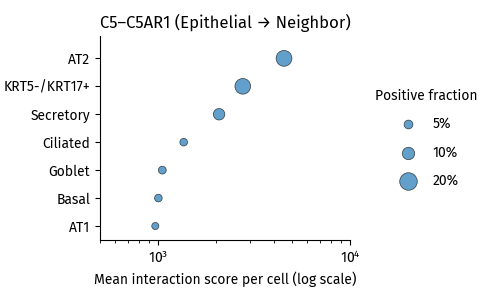

In [77]:
plot_df = summary_df.sort_values("mean_score", ascending=True).copy()

size_scale = 800
sizes = plot_df["positive_fraction"] * size_scale

plot_df["mean_score_plot"] = plot_df["mean_score"].replace(0, np.nan)

fig, ax = plt.subplots(figsize=(5, 3))
fig.subplots_adjust(left=0.2, bottom=0.2, right=0.7)
y = np.arange(len(plot_df))

dot_color = "tab:blue"

ax.scatter(
    plot_df["mean_score_plot"],
    y,
    s=sizes,
    color=dot_color,
    alpha=0.7,
    edgecolors="black",
    linewidths=0.5
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df.index)
ax.set_xscale("log")
ax.set_xlim(50e1, 10e3)
ax.set_ylim(-0.5, 6.8)
ax.set_xlabel("Mean interaction score per cell (log scale)")
ax.set_ylabel("")
ax.set_title("C5–C5AR1 (Epithelial → Neighbor)")

legend_fracs = [0.05, 0.1, 0.2]

handles = [
    ax.scatter(
        [], [],
        s=f * size_scale,
        color=dot_color,
        alpha=0.7,
        edgecolors="black",
        linewidths=0.5
    )
    for f in legend_fracs
]

labels = [f"{f:.0%}" for f in legend_fracs]

ax.legend(
    handles,
    labels,
    title="Positive fraction",
    scatterpoints=1,
    markerscale=1,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(1.05,0.5),
    labelspacing=1
)

ax.spines[["top", "right"]].set_visible(False)

fig.savefig(f"{WORK_PATH}Figure/032_C5_C5AR1_epithelial.png", dpi=500, format="png", bbox_inches=None)

In [78]:
source_df = (
    summary_df[
        ["n_cells", "mean_score", "positive_fraction"]
    ]
    .sort_values("mean_score", ascending=False)
    .reset_index()
    .rename(columns={
        "subtype": "Epithelial_subtype",
        "n_cells": "N_cells",
        "mean_score": "Mean_interaction_score",
        "positive_fraction": "Positive_fraction"
    })
)

source_df.to_csv(f"{WORK_PATH}CSV/032_C5_C5AR1_epithelial_sender_source_data.csv", index=False)

In [79]:
sender_subtypes = ["KRT5-/KRT17+","AT2"]

subtype_map = meta["subtype"].to_dict()
valid_set = set(valid_indices)

sub_indices = {
    key: set(meta.index[meta["subtype"] == key]) & valid_set
    for key in sender_subtypes
}

n_sub = {
    key: len(sub_indices[key])
    for key in sender_subtypes
}

sender_receiver_scores = {
    key: defaultdict(float)
    for key in sender_subtypes
}

receiver_scores = {
    key: defaultdict(float)
    for key in sender_subtypes
}

sender_type_map = {
    idx: subtype
    for subtype, indices in sub_indices.items()
    for idx in indices
}

for (s, r), score in obj_i2n.items():

    sender_subtype = sender_type_map.get(s)

    if sender_subtype is None:
        continue

    receiver_subtype = subtype_map.get(r)

    if receiver_subtype is None:
        continue

    val = float(np.asarray(score).sum())

    sender_receiver_scores[sender_subtype][
        (s, receiver_subtype)
    ] += val

    receiver_scores[sender_subtype][r] += val

In [80]:
receiver_summary_dict = {key:pd.DataFrame for key in sender_subtypes}
for key in sender_subtypes:
    # sender × receiver subtype
    sr_df = pd.DataFrame(
        [(s, subtype, score) for (s, subtype), score in sender_receiver_scores[key].items()],
        columns=["sender_idx", "receiver_subtype", "score"]
    )
    
    receiver_summary = (
        sr_df.groupby("receiver_subtype")
        .agg(
            total_score=("score", "sum"),
            n_positive_senders=("score", lambda x: (x > 0).sum())
        )
    )
    
    receiver_summary["n_sub"] = n_sub[key]
    receiver_summary["mean_score"] = receiver_summary["total_score"] / n_sub[key]
    receiver_summary["positive_fraction"] =  receiver_summary["n_positive_senders"] / n_sub[key]
    receiver_summary["contribution_pct"] = receiver_summary["total_score"] / receiver_summary["total_score"].sum() * 100
    
    receiver_summary_dict[key] = receiver_summary.sort_values("mean_score", ascending=False)
    

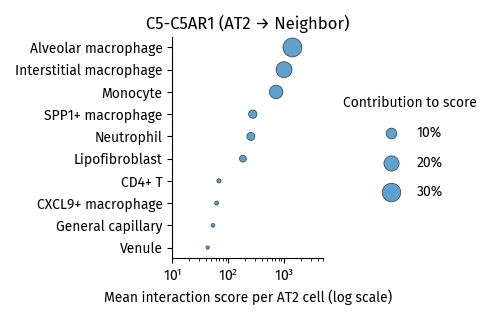

In [81]:
plot_df = receiver_summary_dict["AT2"].sort_values(
    "mean_score", ascending=True
).copy()
plot_df = plot_df.tail(10)

size_scale = 600
sizes = plot_df["contribution_pct"] * size_scale * 0.01

plot_df["mean_score_plot"] = (
    plot_df["mean_score"].replace(0, np.nan)
)


fig, ax = plt.subplots(figsize=(5, 3.2))
fig.subplots_adjust(left=0.32, bottom=0.15, right=0.72)

y = np.arange(len(plot_df))

dot_color = "tab:blue"

ax.scatter(
    plot_df["mean_score_plot"],
    y,
    s=sizes,
    color=dot_color,
    alpha=0.7,
    edgecolors="black",
    linewidths=0.5
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df.index)
ax.set_xlim(10, 50e2)
ax.set_xscale("log")
ax.set_xlabel("Mean interaction score per AT2 cell (log scale)")
ax.set_title("C5-C5AR1 (AT2 → Neighbor)")

legend_fracs = [0.1, 0.2, 0.3]

handles = [
    ax.scatter(
        [], [],
        s=f * size_scale,
        color=dot_color,
        alpha=0.7,
        edgecolors="black",
        linewidths=0.5
    )
    for f in legend_fracs
]

ax.legend(
    handles,
    [f"{f:.0%}" for f in legend_fracs],
    title="Contribution to score",
    scatterpoints=1,
    labelspacing=1.1,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(1.05, 0.5)
)

ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

fig.savefig(f"{WORK_PATH}Figure/032_C5_C5AR1_AT2.png", dpi=500, format="png", bbox_inches=None)

In [82]:
source_df = (
    receiver_summary_dict["AT2"][
        ["n_positive_senders", "mean_score", "contribution_pct"]
    ]
    .sort_values("mean_score", ascending=False)
    .reset_index()
    .rename(columns={
        "receiver_subtype": "Reciever_subtype",
        "n_positive_senders": "N_positive_senders",
        "mean_score": "Mean_interaction_score",
        "contribution_pct": "Contribution_to_score",
    })
)

source_df.to_csv(f"{WORK_PATH}CSV/032_C5_C5AR1_AT2_source_data.csv", index=False)

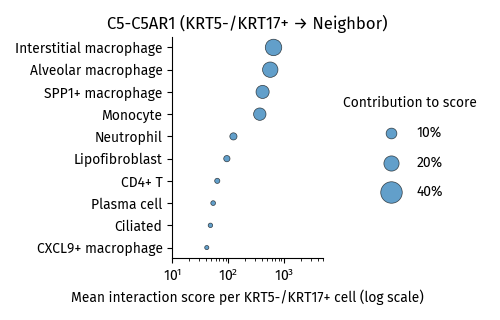

In [83]:
plot_df = receiver_summary_dict["KRT5-/KRT17+"].sort_values(
    "mean_score", ascending=True
).copy()
plot_df = plot_df.tail(10)

size_scale = 600
sizes = plot_df["contribution_pct"] * size_scale * 0.01

plot_df["mean_score_plot"] = (
    plot_df["mean_score"].replace(0, np.nan)
)


fig, ax = plt.subplots(figsize=(5, 3.2))
fig.subplots_adjust(left=0.32, bottom=0.15, right=0.72)

y = np.arange(len(plot_df))

dot_color = "tab:blue"

ax.scatter(
    plot_df["mean_score_plot"],
    y,
    s=sizes,
    color=dot_color,
    alpha=0.7,
    edgecolors="black",
    linewidths=0.5
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df.index)
ax.set_xlim(10, 50e2)
ax.set_xscale("log")
ax.set_xlabel("Mean interaction score per KRT5-/KRT17+ cell (log scale)")
ax.set_title("C5-C5AR1 (KRT5-/KRT17+ → Neighbor)")

legend_fracs = [0.1, 0.2, 0.4]

handles = [
    ax.scatter(
        [], [],
        s=f * size_scale,
        color=dot_color,
        alpha=0.7,
        edgecolors="black",
        linewidths=0.5
    )
    for f in legend_fracs
]

ax.legend(
    handles,
    [f"{f:.0%}" for f in legend_fracs],
    title="Contribution to score",
    scatterpoints=1,
    labelspacing=1.1,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(1.05, 0.5)
)

ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

fig.savefig(f"{WORK_PATH}Figure/032_C5_C5AR1_517.png", dpi=500, format="png", bbox_inches=None)

In [84]:
source_df = (
    receiver_summary_dict["KRT5-/KRT17+"][
        ["n_positive_senders", "mean_score", "contribution_pct"]
    ]
    .sort_values("mean_score", ascending=False)
    .reset_index()
    .rename(columns={
        "receiver_subtype": "Reciever_subtype",
        "n_positive_senders": "N_positive_senders",
        "mean_score": "Mean_interaction_score",
        "contribution_pct": "Contribution_to_score",
    })
)

source_df.to_csv(f"{WORK_PATH}CSV/032_C5_C5AR1_517_source_data.csv", index=False)

# Directionality of Pathways Over a Specific Continuum Period

In [ ]:
# import pandas as pd
# import numpy as np
# import scipy
# import seaborn as sns
# import matplotlib
# import matplotlib.pyplot as plt
# import matplotlib.gridspec as gridspec
# from collections import defaultdict
# import tqdm
# import pickle
# import scanpy as sc
# import glob
# import os
# from pycirclize import Circos
# from pycirclize.utils import ColorCycler
# from statsmodels.stats.multitest import multipletests
# from Xenium_5K_IPF_constants import EPITHELIAL_SUBTYPE, ALL_SUBTYPE_LIST, TITLE_ABBREVIATION, MAJOR_CLUSTER_COLORS, WORK_PATH

# # Option
# sc.settings.verbosity = 3
# plt.rcParams["font.family"] = "Fira Sans" 
# %matplotlib ipympl


In [ ]:
# pathway_dir = f"{WORK_PATH}Interaction/interaction_scores_Epithelial" 
# celltype = pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv") 
# cellchat_db_f=pd.read_pickle(f"{WORK_PATH}Interaction/interaction_data.pkl")
# position_df=pd.read_csv(f"{WORK_PATH}CSV/021_epithelial_cPosition.csv", index_col="cell_id")


In [ ]:
# subtype_to_major = celltype.set_index("subtype")["cell_type_major"].to_dict()

In [ ]:
# celltype_c = celltype.copy()
# celltype_c["index"]=celltype_c.index
# celltype_c.set_index("cell_id", inplace=True)
# position_df_m = pd.merge(left=position_df, right=celltype_c[["index"]], left_index=True, right_index=True, how="left")

In [ ]:
# cp_bin_n = 5

In [ ]:
# def Cp_bin(x):
#     if x == 1:
#         return cp_bin_n-1
#     else:
#         return int((cp_bin_n*x)//1)
# position_df_m['Cp_bin'] = position_df_m['C_position'].map(lambda x:Cp_bin(x))
# position_df_m["Cp_bin"] = pd.Categorical(position_df_m["Cp_bin"], categories=[n for n in range(cp_bin_n)], ordered=True)

In [ ]:
# cp_bins_counts = pd.crosstab(position_df_m["Cp_bin"], position_df_m["subtype"])
# cp_bins_counts_rt = cp_bins_counts.div(cp_bins_counts.sum(axis=1), axis=0)
# cp_bins_counts_rt

In [ ]:
# # Nei to Epi

# # int_pathway ="TGFB1 - ACVR1B_TGFbR2"
# # int_pathway ="TGFB2 - ACVR1B_TGFbR2"
# # int_pathway ="TGFB3 - ACVR1B_TGFbR2"
# # int_pathway ="POSTN - ITGAV_ITGB3"
# int_pathway ="POSTN - ITGAV_ITGB5"

# to = "nei_to_int"

In [ ]:
# # Epi to Nei

# # int_pathway ="PDGFA - PDGFRA"
# # int_pathway ="PDGFA - PDGFRB"
# int_pathway = "VEGFA - KDR"
# # int_pathway ="C5 - C5AR1"

# to = "int_to_nei"

In [ ]:
# n_cells_cutoff = 0.03

# epi_to_i = {k: i for i, k in enumerate(EPITHELIAL_SUBTYPE)}
# all_to_i = {k: i for i, k in enumerate(ALL_SUBTYPE_LIST)}

# int_cp_bins_arr = {
#     cp: np.zeros((len(ALL_SUBTYPE_LIST), len(EPITHELIAL_SUBTYPE)), dtype=float)
#     for cp in range(cp_bin_n)
# }

# subtype_map = celltype_c.set_index("index")["subtype"].to_dict()
# cp_map = position_df_m.set_index("index")["Cp_bin"].to_dict()

# with open(os.path.join(pathway_dir, f"{int_pathway}.pkl"), "rb") as f:
#     obj = pickle.load(f)[to]

# if to == "nei_to_int":
#     for (s, r), score in obj.items():
#         cp_bin = cp_map.get(r)
#         if cp_bin is None:
#             continue
    
#         sen_type = subtype_map[s]
#         rec_type = subtype_map[r]
#         if cp_bins_counts_rt.loc[cp_bin, rec_type] > n_cells_cutoff:
#             int_cp_bins_arr[cp_bin][all_to_i[sen_type], epi_to_i[rec_type]] += score/cp_bins_counts.loc[cp_bin,rec_type]
#         else:
#             int_cp_bins_arr[cp_bin][all_to_i[sen_type], epi_to_i[rec_type]] += 0
            
# else:  # "int_to_nei"
#     for (s, r), score in obj.items():
#         cp_bin = cp_map.get(s)
#         if cp_bin is None:
#             continue
    
#         sen_type = subtype_map[s]
#         rec_type = subtype_map[r]
#         if cp_bins_counts_rt.loc[cp_bin, sen_type] > n_cells_cutoff:
#             int_cp_bins_arr[cp_bin][all_to_i[rec_type], epi_to_i[sen_type]] += score/cp_bins_counts.loc[cp_bin, sen_type]
#         else:
#             int_cp_bins_arr[cp_bin][all_to_i[rec_type], epi_to_i[sen_type]] += 0

# int_cp_bins = {
#     cp: pd.DataFrame(
#         int_cp_bins_arr[cp],
#         index=ALL_SUBTYPE_LIST,
#         columns=EPITHELIAL_SUBTYPE
#     )
#     for cp in range(cp_bin_n)
# }

# cut_bin_type = (cp_bins_counts_rt <= n_cells_cutoff).stack()
# cut_bin_type = cut_bin_type[cut_bin_type].index.tolist()

In [ ]:
# records = []
# global_max = max(arr.max() for arr in int_cp_bins_arr.values())

# for cp_bin, arr in int_cp_bins_arr.items():
#     n_row, n_col = arr.shape

#     for i in range(n_row):
#         for j in range(n_col):
#             score = arr[i, j]
#             records.append({
#                 "cp_bin": cp_bin,
#                 "ALL_idx": int(i),
#                 "EPI_idx": int(j),
#                 "score": score,
#                 "scaled_global": score / global_max if global_max > 0 else 0.0,
#             })

# df_int = pd.DataFrame(records)


In [ ]:
# df_nz = df_int[df_int["score"] > 0].copy()
# pct = 5
# thr = df_nz["score"].quantile(1-pct/100) 
# top_df = df_nz[df_nz["score"] >= thr].sort_values("score", ascending=False)
# top_df["Nei_type"] = top_df["ALL_idx"].map(lambda x: subtype_to_major[ALL_SUBTYPE_LIST[x]])
# top_df["Epi_subtype"] = top_df["EPI_idx"].map(lambda x: EPITHELIAL_SUBTYPE[x])

In [ ]:
# n_epi = len(EPITHELIAL_SUBTYPE)
# n_all = len(ALL_SUBTYPE_LIST)

# sectors_name = [f"Epi\n[{n/cp_bin_n} - {(n+1)/cp_bin_n}]" for n in range(cp_bin_n)]+["Nei"] 
# sectors_subtype_n = [n_epi]*cp_bin_n+[n_all]
# epi_sub_list = [list(np.arange(0,n_epi, 1))]*cp_bin_n

# for cp, ty in cut_bin_type:
#     sectors_subtype_n[cp] -= 1
#     epi_sub = epi_sub_list[cp].copy()
#     rm = EPITHELIAL_SUBTYPE.index(ty)
#     epi_sub.remove(rm)
#     epi_sub_list[cp] = epi_sub.copy()

# sectors = {name:l for name,l in zip(sectors_name, sectors_subtype_n)}

# int_spa_major = 25
# int_spa_minor = (180-int_spa_major)*(n_all-sum(sectors_subtype_n[:-1]))/(4*n_all)
# spaces = [int_spa_minor] * 4 + [int_spa_major]*2

In [ ]:
# top_df_new = []
# for n,e in enumerate(epi_sub_list):
#     if len(e) < n_epi:
#         temp_df = top_df[top_df["cp_bin"]==n].copy()
#         temp_df["EPI_idx"] = temp_df["EPI_idx"].map(lambda x: e.index(x))
#         top_df_new.append(temp_df)
#     else:
#         top_df_new.append(top_df[top_df["cp_bin"]==n].copy())
# top_df_new = pd.concat(top_df_new)

In [ ]:
# circos = Circos(sectors, space=spaces, start=-360+int_spa_major/2, end=int_spa_major/2)

# sm_cp = plt.get_cmap("plasma",cp_bin_n)
# sm_epi = plt.get_cmap("Set3",12)
# sm_epi_list = [matplotlib.colors.rgb2hex(sm_epi(i))+"ff" for i in range(sm_epi.N)]
# sm_epi_col = [[sm_epi_list[n] for n in epi_sub_list[m]] for m in range(cp_bin_n)]

# bar_max=0
# for n in range(cp_bin_n):
#     if sum(top_df_new["cp_bin"]==n) >0:
#         bar_max = max(pd.DataFrame({"score":top_df_new[top_df_new["cp_bin"]==n].groupby("EPI_idx")["score"].sum()},index=np.arange(0,n_epi,1))["score"].max(), bar_max)
    
# if bar_max > 8000:
#     bar_max = ((bar_max//5000)+1)*5000
# elif bar_max > 2000:
#     bar_max = ((bar_max//1000)+1)*1000
# elif bar_max > 1000:
#     bar_max = ((bar_max//200)+1)*200
# else:
#     bar_max = 1000

# arrow_rad = []
    
# for m,sector in enumerate(circos.sectors):
#     # subtype colors
#     track_subcol = sector.add_track((45, 50))
#     track_subcol.axis()
    
#     # subtype names
#     track_subtype = sector.add_track((51, 51))
#     track_subtype.axis()
    
#     if sector.name.startswith("Ep"):
#         sub_list = [EPITHELIAL_SUBTYPE[n] for n in epi_sub_list[m]]
#     elif sector.name.startswith("Ne"):
#         sub_list = ALL_SUBTYPE_LIST[::-1]
    
#     for i in range(int(track_subtype.size)):
#         start, end = i, i + 1

#         track_subtype.axis(fc="white", ec="white")
#         track_subtype.text(sub_list[i], (end + start) / 2, size=12)

#         if sector.name.startswith("Ep"):
#             track_subcol.rect(start, end, fc=sm_epi(epi_sub_list[m][start]))
#         elif sector.name.startswith("Ne"):
#             track_subcol.rect(start, end, fc=MAJOR_CLUSTER_COLORS[subtype_to_major[ALL_SUBTYPE_LIST[n_all-start-1]]])

#     if sector.name.startswith("Ep"): 
#         # Bar Track
#         track_bar = sector.add_track((72, 92), r_pad_ratio=0.1)
#         track_bar.axis()
#         track_bar.grid(y_grid_num=3, color="#555555", ls="--", lw=0.8)
#         df_bin = top_df_new[top_df_new["cp_bin"]==m]
#         epi_score = pd.DataFrame({"score":df_bin.groupby("EPI_idx")["score"].sum()},index=np.arange(0,len(epi_sub_list[m]),1)).fillna(0)
#         track_bar.bar(np.arange(0,len(epi_score),1)+0.5, epi_score["score"], vmax=bar_max, color=sm_epi_col[m], ec="grey")

#         # Continuum position colors
#         track_subcol = sector.add_track((93, 100))
#         track_subcol.axis(fc=sm_cp(m))
#         if m < cp_bin_n/2:
#             track_subcol.text(sector.name.split("\n")[1],size=11, color="white", weight=500)
#         else:
#             track_subcol.text(sector.name.split("\n")[1],size=11, color="black", weight=400)
            
#         if m == 0:
#             track_bar.yticks(np.linspace(0, bar_max, 3), [0, int(bar_max/2), int(bar_max)], side="left", line_kws=dict(color="grey", lw=0.8))
#             track_subcol.yticks([1], ["Continuum-position intervals"], vmin=0, vmax=2, side="left", line_kws=dict(lw=1), text_kws=dict(weight=500))

#         else:
#             track_bar.yticks(np.linspace(0, bar_max, 3), side="left", line_kws=dict(color="grey", lw=0.8))
    
#         arrow_rad.append(sector.rad_lim)
    

# for _,d in top_df_new.iterrows():
#     if to == "nei_to_int":
#         circos.link(("Nei", n_all-1-d["ALL_idx"], n_all-d["ALL_idx"]), (sectors_name[int(d["cp_bin"])], d["EPI_idx"]+1, d["EPI_idx"]),
#                     direction=1, fc=MAJOR_CLUSTER_COLORS[d["Nei_type"]], alpha=0.3, ec="black", lw=1)
#     else:        
#         circos.link((sectors_name[int(d["cp_bin"])], d["EPI_idx"]+1, d["EPI_idx"]), ("Nei", n_all-1-d["ALL_idx"], n_all-d["ALL_idx"]), 
#                     direction=1, fc=sm_epi_col[d["cp_bin"]][d["EPI_idx"]], alpha=0.3, ec="black", lw=1)


# fig = circos.plotfig(figsize=(8.5,8))

# ax = fig.axes[0]

# # Arrows of continuum position intervals
# for m in range(cp_bin_n-1):
#     rad_int = arrow_rad[m+1][0]-arrow_rad[m][1]
#     # arrow body
#     theta = np.linspace(arrow_rad[m][1]+rad_int/8, arrow_rad[m+1][0]-rad_int/3.5, 300)
#     r = np.full_like(theta, 96)
#     ax.plot(theta, r, lw=6, color="#4a4a4a")
    
#     # arrow head
#     tri = plt.Polygon(((arrow_rad[m+1][0]-rad_int/3, 92),(arrow_rad[m+1][0]-rad_int/3,100),(arrow_rad[m+1][0]-rad_int/20,96)),fc="#4a4a4a")
#     ax.add_patch(tri)

# # modify
# cx, cy = ax.transAxes.transform((0.5, 0.5))

# for txt in ax.texts:
#     label = txt.get_text()
#     if label[:2] in ["[0", "Sc"]:
#         continue
#     if label[:2] in ["Co"]:
#         txt.set_rotation(0)
#         txt.set_size(12)
#         continue
#     if label[-1:] in ["0"]:
#         txt.set_rotation(0)
#         txt.set_size(10)
#         continue
        
#     rot = txt.get_rotation()
#     if rot > 90:
#         txt.set_rotation(rot + 90)
#     else:
#         txt.set_rotation(rot - 90)

#     x_disp, y_disp = txt.get_transform().transform(txt.get_position())

#     txt.set_va("center")
#     txt.set_rotation_mode("anchor")

#     if x_disp >= cx:
#         # The label on the right is left-aligned.
#         txt.set_ha("left")
#     else:
#         # The label on the leftt is right-aligned.
#         txt.set_ha("right")
#     if label in TITLE_ABBREVIATION:
#         txt.set_text(TITLE_ABBREVIATION[label])
#     if label[-2:-1] == "_":
#         txt.set_text(label[:-2])

# count_ax = fig.add_axes([0.12, 0.06, 0.05, 0.15])
# count_ax.set(xlim=(-0.6, 0.6),ylim=(0, 105))
# count_ax.spines["top"].set_visible(False)
# count_ax.spines["right"].set_visible(False)
# count_ax.set_xticks([])
# count_ax.set_title(f"Top {pct}% contribution\nto total score (%)")
# count_ax.set_yticks([0, 50, 100], [0, 50, 100], fontsize=12)
# per = 100*top_df_new["score"].sum()/df_int["score"].sum()
# count_ax.bar(x=0, height=per, color="grey", ec="black")

# fig.text(s=f"{int_pathway}",x=0.18,y=0.85, size=16, va="bottom", ha="center", weight=800)
# fig.text(s=f"(top {pct}% score)",x=0.18,y=0.85, size=15, va="top", ha="center")

# if to == "nei_to_int":
#     fig.text(s="Sender (neighbor)",x=0.08,y=0.5, size=14, rotation=90,  ha="left", va="center", weight=700)
#     fig.text(s="Reciever (epithelial)",x=0.98,y=0.5, size=14, rotation=270, ha="right", va="center", weight=700)
# else:
#     fig.text(s="Reciever (neighbor)",x=0.08,y=0.5, size=14, rotation=90,  ha="left", va="center", weight=700)
#     fig.text(s="Sender (epithelial)",x=0.98,y=0.5, size=14, rotation=270, ha="right", va="center", weight=700)

# # plt.savefig(f"{WORK_PATH}/Figure/032_interaction_along_CPinterval_{to}_{int_pathway}.png", dpi=300, format="png", bbox_inches=None)

# Downstream Analysis Between Signal Positive and Negative

In [1]:
import pandas as pd
import numpy as np
import scanpy as sc
import squidpy as sq
import decoupler as dc
import gseapy as gp
import scipy
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from collections import defaultdict
import tqdm
import pickle
import os
import glob
from pydeseq2.dds import DeseqDataSet, DefaultInference
from pydeseq2.ds import DeseqStats
from statsmodels.stats.multitest import multipletests
from Xenium_5K_IPF_constants import ALL_SUBTYPE_LIST, EPITHELIAL_SUBTYPE, WORK_PATH

os.makedirs(f"{WORK_PATH}Figure/032_Downstream_analysis/", exist_ok=True)

# Option
sc.settings.verbosity = 3
plt.rcParams["font.family"] = "Fira Sans" 
%matplotlib ipympl


In [2]:
celltype = pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv") 
cellchat_db_f=pd.read_pickle(f"{WORK_PATH}Interaction/interaction_data.pkl")

In [3]:
interest_label = "Epithelial"     
pathway_dir = f"{WORK_PATH}Interaction/interaction_scores_Epithelial" 

In [4]:
celltype_c = celltype.copy()
celltype_c["index"]=celltype_c.index
celltype_c.set_index("cell_id", inplace=True)

In [5]:
adata = sc.read_h5ad(f"{WORK_PATH}AnnData/integrated_anndata.h5ad")
adata = adata[celltype_c.index,].copy()
adata.obs = pd.merge(adata.obs, celltype_c[["cell_type_major", "subtype"]], left_index=True, right_index=True)

In [6]:
# int_pathway ="TGFb"
int_pathway ="PERIOSTIN"

interactions = cellchat_db_f[cellchat_db_f["pathway_name"]==int_pathway]["interaction_name"]
dir_name = int_pathway

rej = list(set(cellchat_db_f[cellchat_db_f["pathway_name"]==int_pathway]["gene_list"].sum()))

In [ ]:
int_pathway = "C5"
interactions = ["C5 - C5AR1"]

In [ ]:
int_pathway = "HGF"
interactions = ["HGF - MET"]

In [ ]:
dir_name = interactions[0]

assert os.path.isfile(f"{pathway_dir}/{dir_name}.pkl"), "Enter the interaction pair by the wrong name."

rej = list(set(cellchat_db_f[cellchat_db_f["interaction_name"].isin(interactions)]["gene_list"].sum()))

In [7]:
fig_dir = f"{WORK_PATH}Figure/032_Downstream_analysis/{dir_name}/"
os.makedirs(fig_dir, exist_ok=True)

In [8]:
results_path_df = {
    "nei_to_int":defaultdict(float),
    "int_to_nei":defaultdict(float)
}

for inter in tqdm.tqdm(interactions):
    with open(os.path.join(pathway_dir, f"{inter}.pkl"), "rb") as f:
        obj = pickle.load(f)  # {"direction":{(send_idx, reci_idx):values}

        obj_n2i = obj["nei_to_int"]  # (send_idx, reci_idx):values
        obj_i2n = obj["int_to_nei"]
        
        for (_, i), score in obj_n2i.items():
            results_path_df["nei_to_int"][i] += score
        
        for (i, _), score in obj_i2n.items():
            results_path_df["int_to_nei"][i] += score


100%|█████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:00<00:00,  5.34it/s]


In [9]:
adata_m = adata[adata.obs["cell_type_major"]==interest_label].copy()

In [10]:
sub_d = adata_m.obs["subtype"].unique()
sub_d = [s for s in ALL_SUBTYPE_LIST if s in sub_d]
adata_m.obs["subtype"] = pd.Categorical(adata_m.obs["subtype"], categories=sub_d, ordered=True)

In [11]:
pathawy_score = {
    "nei_to_int":pd.DataFrame,
    "int_to_nei":pd.DataFrame
}

for direc in ["nei_to_int", "int_to_nei"]:
    pathawy_score[direc]=pd.DataFrame.from_dict(results_path_df[direc], orient="index", columns=[f"int_scores"])
    celltype_c[f"int_{direc}"] = pd.Categorical(celltype_c["index"].isin(pathawy_score[direc].index).map({True: "positive", False: "negative"}))
    adata_m.obs = pd.merge(left=adata_m.obs, right=celltype_c[celltype_c["cell_type"]==interest_label][[f"int_{direc}"]], left_index=True, right_index=True, how="inner")

In [12]:
adata_m = adata_m[:,[g for g in adata.var_names if g not in rej]]

In [13]:
ttt = "int_nei_to_int"

In [ ]:
# ttt = "int_int_to_nei"

In [14]:
adata_m.obs = adata_m.obs.rename(columns={ttt: "Signal"})

In [15]:
pdata = dc.pp.pseudobulk(
    adata=adata_m,
    sample_col="sample",
    groups_col=["subtype", "Signal"] ,
    mode="sum",
)

In [16]:
pdata.obs["Signal"] = pd.Categorical(pdata.obs["Signal"], categories=["positive", "negative"], ordered=True)
pdata.obs["subtype"] = pd.Categorical(pdata.obs["subtype"], categories=EPITHELIAL_SUBTYPE, ordered=True)

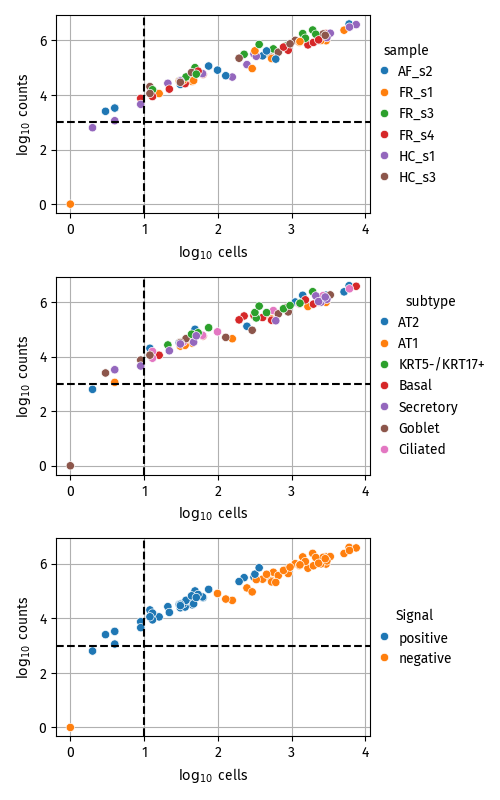

In [17]:
dc.pl.filter_samples(
    adata=pdata,
    groupby=["sample", "subtype", "Signal"],
    min_cells=10,
    min_counts=1000,
    figsize=(5, 8),
)
plt.savefig(f"{fig_dir}nei2epi_signal_QC.png", dpi=500, format="png", bbox_inches=None)

In [18]:
dc.pp.filter_samples(pdata, min_cells=10, min_counts=1000)

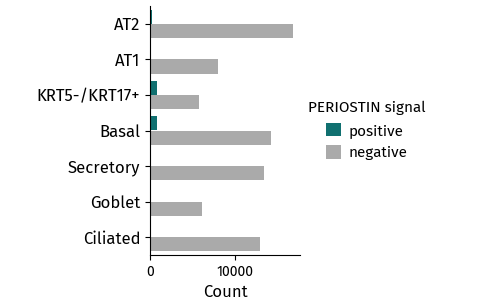

In [19]:
plt.figure(figsize=(5,3))
plt.subplots_adjust(left=0.3, right=0.6, top=0.98, bottom=0.15)
sns.countplot(
    data=adata_m.obs,
    y="subtype",
    hue="Signal",
    hue_order=["positive", "negative"],
    palette={"positive": "teal", "negative": "#aaaaaa"},  
    legend=False,
)
plt.legend(["positive", "negative"], title=f"{dir_name} signal", fontsize=11, title_fontsize=11, loc='center left', bbox_to_anchor=(1, 0.5))
plt.ylabel("")
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.tick_params("y", labelsize=12)
plt.xlabel("Count", fontsize=12)

plt.show()

plt.savefig(f"{fig_dir}nei2epi_signal_count.png", dpi=500, format="png", bbox_inches=None)

In [20]:
pd.DataFrame(adata_m.obs.groupby("subtype")["Signal"].value_counts()).to_csv(f"{fig_dir}nei2epi_signal_count.csv", index=True)

In [21]:
sub_adata_list = [pdata[pdata.obs["subtype"]==e] for e in sub_d]

In [22]:
def DESeq2_func(data):
    # Build DESeq2 object
    inference = DefaultInference(n_cpus=8)
    dds = DeseqDataSet(
        adata=data,
        design_factors=["Signal", "sample"],
        refit_cooks=True,
        inference=inference,
    )
    
    # Compute LFCs
    dds.deseq2()
    
    # Extract contrast between conditions
    stat_res = DeseqStats(dds, contrast=["Signal", "positive", "negative"], inference=inference)
    
    # Compute Wald test
    stat_res.summary()
    
    return stat_res.results_df

## unique term comparation (TGFb, HGF)

In [ ]:
hoge = gp.get_library(f"{WORK_PATH}h.all.v2025.1.Hs.symbols.gmt")
emt_set = {"EPITHELIAL_MESENCHYMAL_TRANSITION":hoge["HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION"]}

In [ ]:
pre_res_list = []
for sub in sub_adata_list:
    res = DESeq2_func(sub)    
    rank_sub = (
        res[['stat']]
        .dropna()
        .squeeze()
        .sort_values(ascending=False)
    )
    rank_sub = rank_sub.loc[~rank_sub.index.duplicated(keep=False)].copy()
    
    pre_res = gp.prerank(
    rnk=rank_sub,
    gene_sets=emt_set,
    processes=4,
    permutation_num=5000,
    min_size=15,
    max_size=500,
    outdir=None,
    seed=42,
    )
    pre_res_list.append(pre_res.res2d.iloc[0])
emt_df = pd.DataFrame({key:val for key, val in zip(sub_d, pre_res_list)}).T

In [ ]:
fuga = emt_df[["NES", "NOM p-val"]].astype(float).copy()

In [ ]:
fuga["log10 p-val"] = -np.log10(fuga["NOM p-val"].clip(1e-3, 1))

In [ ]:
# HGF-MET
adtxt = {
    "AT2":["left", "bottom", (0, -0.1)],
    "AT1":["center", "top", (-0.1, -0.1)],
    "Secretory":["left", "bottom", (-0.05, 0.05)],
}
tit = "HGF-MET"

In [ ]:
# TGFb
adtxt = {
    "AT1":["right", "bottom", (0.15, 0.05)],
    "KRT5-/KRT17+":["left", "top", (0, 0)],
    "Basal":["left", "bottom", (-0.15, 0.1)],
    "Ciliated":["right", "top", (0, 0)],
}
tit = "TGFb"

In [ ]:
fig,ax=plt.subplots(figsize=(4,4))
ax.set_xlim(-3, 3)
ax.set_ylim(0,3.2)
ax.set_xlabel("NES",fontsize=13)
ax.set_ylabel("$-\log_{10}{(P \; \mathrm{value})}$", fontsize=13)
for i, row in fuga.iterrows():
    nes = row["NES"]
    pvl = row["log10 p-val"]
    if pvl >= -np.log10(0.05):
        if nes > 0:
            ax.scatter(y=pvl, x=nes, c="red", edgecolor="black", alpha=0.7)
        else:
            ax.scatter(y=pvl, x=nes, c="blue", edgecolor="black", alpha=0.7)
    else:
        ax.scatter(y=pvl, x=nes, c="grey", edgecolor="black", alpha=0.7)

    marg = 0.1
    if i in adtxt:
        v = adtxt[i]
        if v[0] == "right":
            marg = -marg
        ax.text(y=pvl+v[2][1], x=nes+v[2][0]+marg, s=i, fontsize=12, ha=v[0], va=v[1])
    else:
        ax.text(y=pvl, x=nes+marg, s=i, fontsize=12)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.axhline(y=-np.log10(0.05), c="grey", ls="--")
ax.axvline(x=0, c="grey", ls="--")
ax.set_yticks(ticks=[0, 1, 2, 3], labels=["0", "1", "2", "3<"], fontsize=12)
ax.set_title(f"{tit}", weight=500, fontsize=13)


fig.tight_layout()

plt.savefig(f"{fig_dir}nei2epi_emt_volcano.png", dpi=500, format="png", bbox_inches=None)

In [ ]:
df_source = (
    fuga[["NES", "log10 p-val"]]
    .copy()
    .rename(columns={
        "log10 p-val": "Negative_log10_P_value"
    })
)

df_source.index.name = "Gene_set"
df_source = df_source.reset_index()

df_source["P_value"] = 10 ** (-df_source["Negative_log10_P_value"])

df_source["Significant_P_less_0.05"] = df_source["P_value"] < 0.05


df_source.to_csv(f"{fig_dir}nei2epi_emt_volcano.csv", index=True)

## each subtype comparation (Periostin, C5)

In [23]:
sub_adata_list.append(pdata)
sub_d.append(interest_label)

In [24]:
nnn = 2
sub_d[nnn]

'KRT5-/KRT17+'

In [25]:
pdata_s = sub_adata_list[nnn].copy()

In [26]:
results_df = DESeq2_func(pdata_s)    

Using None as control genes, passed at DeseqDataSet initialization


/tmp/ipykernel_4292/1340724617.py:4: DeprecationWarning: design_factors is deprecated and will soon be removed.Please consider providing a formulaic formula using the design argumentinstead.
  dds = DeseqDataSet(
Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 0.26 seconds.

Fitting dispersion trend curve...
/home/s_nakamura/test_env/lib/python3.12/site-packages/pydeseq2/dds.py:807: UserWarning: The dispersion trend curve fitting did not converge. Switching to a mean-based dispersion trend.
  self._fit_parametric_dispersion_trend(vst)
... done in 0.05 seconds.

Fitting MAP dispersions...
... done in 0.43 seconds.

Fitting LFCs...
... done in 0.32 seconds.

Calculating cook's distance...
... done in 0.00 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 0.18 seconds.



Log2 fold change & Wald test p-value: Signal positive vs negative
           baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
A2ML1      2.178893        0.636052  0.710791  0.894851  0.370867  0.784235
AAMP      95.257481       -0.188627  0.168311 -1.120703  0.262414  0.693489
AAR2      34.021568       -0.280337  0.244096 -1.148472  0.250774  0.685990
AARSD1    29.379995        0.024892  0.266806  0.093296  0.925669  0.983423
ABAT      16.696207       -0.847707  0.304751 -2.781639  0.005409  0.083333
...             ...             ...       ...       ...       ...       ...
ZSCAN26   19.370070        0.022905  0.276265  0.082910  0.933923  0.986128
ZSWIM6    24.812391        0.288169  0.252404  1.141699  0.253579  0.687042
ZUP1      19.259217        0.220813  0.355256  0.621559  0.534232  0.873853
ZYG11B    30.503657       -0.196645  0.269481 -0.729717  0.465563  0.839963
ZYX      141.261752        0.665160  0.169837  3.916458  0.000090  0.004359

[4997 rows x 6 column

<>:2: SyntaxWarning: invalid escape sequence '\l'
<>:3: SyntaxWarning: invalid escape sequence '\l'
<>:2: SyntaxWarning: invalid escape sequence '\l'
<>:3: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_4292/4216962757.py:2: SyntaxWarning: invalid escape sequence '\l'
  plt.ylabel("$-\log_{10}{(P \; \mathrm{value})}$", fontsize=12)
/tmp/ipykernel_4292/4216962757.py:3: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel("$\log_{2}{(\mathrm{fold \; change})}$", fontsize=12)


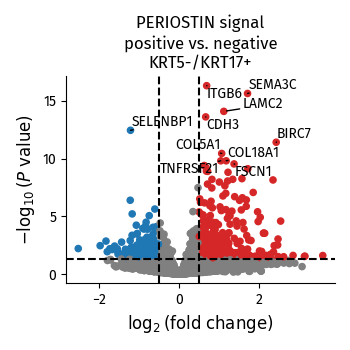

In [27]:
dc.pl.volcano(results_df, x="log2FoldChange", y="pvalue", figsize=(3.5,3.5), top=10)
plt.ylabel("$-\log_{10}{(P \; \mathrm{value})}$", fontsize=12)
plt.xlabel("$\log_{2}{(\mathrm{fold \; change})}$", fontsize=12)
plt.title(f"{dir_name} signal\npositive vs. negative\n{sub_d[nnn]}", fontsize=12)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.savefig(f"{fig_dir}nei2epi_signal_volcano_{sub_d[nnn].replace("/","_")}.png", dpi=500, format="png", bbox_inches=None)

In [28]:
rank_s = (
    results_df[['stat']]
    .dropna()
    .squeeze()
    .sort_values(ascending=False)
)
rank_s = rank_s.loc[~rank_s.index.duplicated(keep=False)].copy()

In [29]:
got = [
    'MSigDB_Hallmark_2020',
    'KEGG_2019_Mouse',
    'KEGG_2021_Human',
    'Reactome_Pathways_2024',
    'GO_Biological_Process_2025',
    'GO_Molecular_Function_2025',
    f"{WORK_PATH}h.all.v2025.1.Hs.symbols.gmt"
]

ggg = 6

In [30]:
prerank_res = gp.prerank(
    rnk=rank_s,
    gene_sets=got[ggg],
    processes=4,
    permutation_num=5000,
    min_size=15,
    max_size=500,
    outdir=None,
    seed=42,
)

/tmp/ipykernel_4292/1507844788.py:1: DeprecationWarning: processes is deprecated; use threads
  prerank_res = gp.prerank(
2026-11-24 00:51:26,296 [WARNING] Duplicated values found in preranked stats: 0.68% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


In [31]:
df_q = prerank_res.res2d
df_q = df_q[df_q["FDR q-val"]<0.05]
df_q = df_q[["Term", "NES", "FDR q-val"]]
df_q["Term"] = [n[9:] for n in df_q["Term"]]

In [32]:
# save
save_df = prerank_res.res2d[[c for c in prerank_res.res2d.columns if c != "Name"]].copy()
save_df["Tag %"] = "\'"+save_df["Tag %"] 
save_df["Term"] = [n[9:] for n in save_df["Term"]]
save_df.set_index("Term").to_csv(f"{WORK_PATH}CSV/032_{int_pathway}_{sub_d[nnn].replace("/","")}_{prerank_res.res2d.loc[0,"Term"].split("_")[0]}.csv")

In [33]:
eps = 0.0005
neglogFDR = -np.log10(np.clip(df_q["FDR q-val"].values.astype(float), eps, 1.0))
df_q["-logFDR"] = neglogFDR

plot_df = df_q.sort_values("NES", ascending=False)

# colormap
cmap = matplotlib.colormaps.get_cmap("viridis")
if 0.01 < df_q["FDR q-val"].values.min():
    norm = matplotlib.colors.Normalize(vmin=-np.log10(0.05),vmax=-np.log10(0.01))
    ticks = -np.log10([0.05, 0.02, 0.01])
    tick_label = ["0.05", "0.02", "0.01"]
elif 0.001 <  df_q["FDR q-val"].values.min():
    norm = matplotlib.colors.Normalize(vmin=-np.log10(0.05),vmax=-np.log10(0.005))
    ticks = -np.log10([0.05, 0.02, 0.01, 0.005])
    tick_label = ["0.05", "0.02", "0.01", "0.005"]
else:
    norm = matplotlib.colors.Normalize(vmin=-np.log10(0.05),vmax=-np.log10(eps))
    ticks = -np.log10([0.05, 0.005, 0.0005])
    tick_label = ["0.05", "0.005", "0.0005"]
bar_colors = cmap(norm(plot_df["-logFDR"].values))


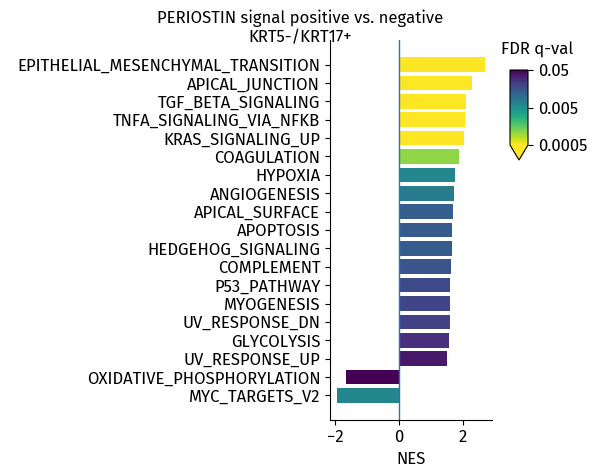

In [34]:
ht = max(5, len(df_q))
tp, bt = 2, 2.5
fig, ax = plt.subplots(figsize=(6, (ht+tp+bt)*0.2))
fig.subplots_adjust(left=0.55, right=0.82, bottom=bt/(ht+tp+bt), top=1-tp/(ht+tp+bt))

ax.barh(
    y=plot_df["Term"],
    width=plot_df["NES"],
    color=bar_colors,
    edgecolor="none"
)

# lune x = 0
ax.axvline(0, linewidth=1)

ax.tick_params("y", labelsize=12)
ax.tick_params("x", labelsize=12)
ax.set_xlabel("NES", size=12)
ax.set_ylabel("")

ax.invert_yaxis()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# colorbar
sm = matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
c_ax = fig.add_axes([0.85, 1-(6+tp)/(ht+tp+bt), 0.03, 4.5/(ht+tp+bt)])
cbar = fig.colorbar(sm, cax=c_ax, extend="max", extendfrac=0.2)
cbar.set_ticks(ticks, labels=tick_label, fontsize=12)

c_ax.set_title("FDR q-val", fontsize=12, loc="center", y=1.1, x=1.5)
cbar.ax.invert_yaxis()

fig.suptitle(f"{dir_name} signal positive vs. negative\n{sub_d[nnn]}", fontsize=12)

plt.savefig(f"{fig_dir}nei2epi_signal_GSEA_{sub_d[nnn].replace("/","_")}_HALLMARK.png", dpi=500, format="png", bbox_inches=None)